# 1. Introduction and Project Objectives

## 1.1 Project Overview

This project analyses e-commerce behaviour data to understand how customers interact with products and identify patterns that may influence purchasing activity. Using event data from an online multi-category store, the analysis examines product views, cart additions, purchases, customer activity, and purchasing trends during October 2019.

The aim is to turn raw event data into meaningful business insights that can help an e-commerce business understand customer engagement, identify potential areas for improvement, and make more informed decisions.

## 1.2 Project Objectives

The main objectives of this project are to:

* **Analyse customer activity:** Examine product views, cart additions, and purchases to understand customer engagement.
* **Evaluate product performance:** Compare product categories, brands, and price bands based on customer activity and purchase events.
* **Identify behavioural trends:** Investigate activity patterns across different days and hours.
* **Understand customer behaviour:** Explore customer segments, purchasing patterns, and potential gaps between browsing, adding to cart, and purchasing.
* **Apply data analysis techniques:** Use Python, statistical analysis, and SQL to explore the data and answer business questions.
* **Visualise findings:** Develop an interactive Tableau dashboard to communicate key trends and product performance insights.

## 1.3 Key Business Questions

This project seeks to answer the following business questions:

1. How do product views, cart additions, and purchases vary throughout October 2019?
2. Which product categories and brands attract the most customer engagement and purchase activity?
3. How does purchase activity vary across different product price bands?
4. Are there differences in customer activity between weekdays and weekends, or across different hours?
5. What customer behaviour segments can be identified from their activity during the month?
6. Which products receive substantial views or cart additions but relatively fewer purchases, and what opportunities might this suggest for improving conversion?

## 1.4 Dataset and Tools

The dataset used is **eCommerce Behavior Data from Multi-Category Store**, obtained from Kaggle and published by mkechinov. It contains event-level records of customer interactions, including product views, cart additions, and purchases, recorded during October 2019.

The project uses the following tools and techniques:

* **Python:** Data cleaning, preparation, exploratory data analysis, and statistical analysis.
* **Pandas and NumPy:** Data manipulation and numerical calculations.
* **Matplotlib and Seaborn:** Data visualisation.
* **SQLite:** SQL queries to investigate product, brand, and price-band performance.
* **Tableau Public:** Dashboard creation and visual presentation of key findings.

The analysis combines these techniques to explore customer behaviour and product performance, with the aim of identifying actionable business insights.


In [33]:
import kagglehub

path = kagglehub.dataset_download(
    "mkechinov/ecommerce-behavior-data-from-multi-category-store",
    path="2019-Oct.csv"
)

print("Dataset path:", path)

Using Colab cache for faster access to the 'ecommerce-behavior-data-from-multi-category-store' dataset.
Dataset path: /kaggle/input/ecommerce-behavior-data-from-multi-category-store/2019-Oct.csv


In [34]:
file_path = "/root/.cache/kagglehub/datasets/mkechinov/ecommerce-behavior-data-from-multi-category-store/versions/8/2019-Oct.csv"

sample_file = "/content/drive/MyDrive/Ecommerce_Analytics/2019-Oct-sample.csv"

print("Original file:", file_path)
print("Sample will be saved to:", sample_file)

Original file: /root/.cache/kagglehub/datasets/mkechinov/ecommerce-behavior-data-from-multi-category-store/versions/8/2019-Oct.csv
Sample will be saved to: /content/drive/MyDrive/Ecommerce_Analytics/2019-Oct-sample.csv


In [6]:
#Read the first 5 rows
import pandas as pd

df_sample = pd.read_csv(file_path, nrows = 5)
df_sample

,event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session
0,2019-10-01 00:00:00 UTC,view,44600062,2103807459595387724,NaN,shiseido,35.79,541312140,72d76fde-8bb3-4e00-8c23-a032dfed738c
1,2019-10-01 00:00:00 UTC,view,3900821,2053013552326770905,appliances.environment.water_heater,aqua,33.20,554748717,9333dfbd-b87a-4708-9857-6336556b0fcc
2,2019-10-01 00:00:01 UTC,view,17200506,2053013559792632471,furniture.living_room.sofa,NaN,543.10,519107250,566511c2-e2e3-422b-b695-cf8e6e792ca8
3,2019-10-01 00:00:01 UTC,view,1307067,2053013558920217191,computers.notebook,lenovo,251.74,550050854,7c90fc70-0e80-4590-96f3-13c02c18c713
4,2019-10-01 00:00:04 UTC,view,1004237,2053013555631882655,electronics.smartphone,apple,1081.98,535871217,c6bd7419-2748-4c56-95b4-8cec9ff8b80d


In [7]:
#Check event types
event_counts = {}
for chunk in pd.read_csv(file_path, usecols=['event_type'], chunksize=1000000):
  counts = chunk["event_type"].value_counts()

  for event, count in counts.items():
    event_counts[event] = event_counts.get(event, 0) + count

print(event_counts)

{'view': 40779399, 'purchase': 742849, 'cart': 926516}


In [8]:
#Check for data types
df_sample = pd.read_csv(file_path, nrows=1000)
df_sample.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   event_time     1000 non-null   object 
 1   event_type     1000 non-null   object 
 2   product_id     1000 non-null   int64  
 3   category_id    1000 non-null   int64  
 4   category_code  634 non-null    object 
 5   brand          857 non-null    object 
 6   price          1000 non-null   float64
 7   user_id        1000 non-null   int64  
 8   user_session   1000 non-null   object 
dtypes: float64(1), int64(3), object(5)
memory usage: 70.4+ KB


## 1.5 Data Cleaning

In [9]:
#Check for missing values

#Create an empty dictionary
missing_counts = {}

for chunk in pd.read_csv(file_path, chunksize = 1000000):
  for column in chunk.columns:
    #Create a temporary holding for each chunk
    missing = chunk[column].isna().sum()
    #Add all the missing columns for each chunk together
    missing_counts[column] = missing_counts.get(column, 0) + missing

print(missing_counts)

{'event_time': np.int64(0), 'event_type': np.int64(0), 'product_id': np.int64(0), 'category_id': np.int64(0), 'category_code': np.int64(13515609), 'brand': np.int64(6117080), 'price': np.int64(0), 'user_id': np.int64(0), 'user_session': np.int64(2)}


In [10]:
#Check for duplicates
duplicate_count = 0

for chunk in pd.read_csv(file_path, chunksize = 1000000):
  duplicate_count += chunk.duplicated().sum()

print("Duplicate rows found:", duplicate_count)

Duplicate rows found: 30220


In [11]:
#Check for any suspious values
invalid_price_count = 0

for chunk in pd.read_csv(file_path, chunksize=1000000):
  invalid_price_count += (chunk["price"] <= 0).sum()

print("Rows with price <= 0:", invalid_price_count)

Rows with price <= 0: 68673


In [12]:
#Get some sample rows of suspicious prices
invalid_prices = pd.read_csv(
    file_path,
    usecols=["event_type", "product_id", "category_code", "brand", "price"],
    chunksize=1_000_000
)

for chunk in invalid_prices:
    invalid_rows = chunk[chunk["price"] <= 0]

    if len(invalid_rows) > 0:
        display(invalid_rows.head(10))
        break

,event_type,product_id,category_code,brand,price
2259,view,53000001,NaN,NaN,0.0
2312,view,53000001,NaN,NaN,0.0
2600,view,7000684,kids.carriage,NaN,0.0
3367,view,4100157,NaN,NaN,0.0
4941,view,23301316,NaN,NaN,0.0
5007,view,13105134,NaN,NaN,0.0
5843,view,31200824,NaN,NaN,0.0
5947,view,23301316,NaN,NaN,0.0
5951,view,31200824,NaN,NaN,0.0
9514,view,32403740,NaN,NaN,0.0


In [13]:
#Check for negative prices
negative_price_count = 0

for chunk in pd.read_csv(file_path, usecols=["price"], chunksize=1_000_000):
    negative_price_count += (chunk["price"] < 0).sum()

print("Rows with negative prices:", negative_price_count)

Rows with negative prices: 0


In [14]:
#Check event_type
event_type = set()

for chunk in pd.read_csv(file_path, chunksize=1000000):
  event_type.update(chunk["event_type"].unique())

print(event_type)

{'cart', 'purchase', 'view'}


## 1.6 Data Preparation and Transformation

In [15]:
#Convert event_time
sample = pd.read_csv(file_path, usecols = ["event_time"], nrows=1000000)
sample["event_time"] = pd.to_datetime(sample["event_time"], utc = True)
sample.head()

,event_time
0,2019-10-01 00:00:00+00:00
1,2019-10-01 00:00:00+00:00
2,2019-10-01 00:00:01+00:00
3,2019-10-01 00:00:01+00:00
4,2019-10-01 00:00:04+00:00


In [16]:
sample["date"] = sample["event_time"].dt.date
sample["hour"] = sample["event_time"].dt.hour
sample["day_of_week"] = sample["event_time"].dt.day_name()

sample.head()

,event_time,date,hour,day_of_week
0,2019-10-01 00:00:00+00:00,2019-10-01,0,Tuesday
1,2019-10-01 00:00:00+00:00,2019-10-01,0,Tuesday
2,2019-10-01 00:00:01+00:00,2019-10-01,0,Tuesday
3,2019-10-01 00:00:01+00:00,2019-10-01,0,Tuesday
4,2019-10-01 00:00:04+00:00,2019-10-01,0,Tuesday


In [17]:
#Create a weekend column
sample["is_weekend"] = sample["event_time"].dt.dayofweek >= 5
sample.head()

,event_time,date,hour,day_of_week,is_weekend
0,2019-10-01 00:00:00+00:00,2019-10-01,0,Tuesday,False
1,2019-10-01 00:00:00+00:00,2019-10-01,0,Tuesday,False
2,2019-10-01 00:00:01+00:00,2019-10-01,0,Tuesday,False
3,2019-10-01 00:00:01+00:00,2019-10-01,0,Tuesday,False
4,2019-10-01 00:00:04+00:00,2019-10-01,0,Tuesday,False


In [18]:
#Checks the categories
categories = set()

for chunk in pd.read_csv(file_path, usecols = ["category_code"], chunksize = 1000000):
  categories.update(chunk["category_code"].dropna().unique())

print("Number of unique category codes:", len(categories))
print("\nSome category codes:")
print(sorted(categories)[:30])

Number of unique category codes: 126

Some category codes:
['accessories.bag', 'accessories.umbrella', 'accessories.wallet', 'apparel.belt', 'apparel.costume', 'apparel.dress', 'apparel.jacket', 'apparel.jeans', 'apparel.jumper', 'apparel.scarf', 'apparel.shirt', 'apparel.shoes', 'apparel.shoes.ballet_shoes', 'apparel.shoes.espadrilles', 'apparel.shoes.keds', 'apparel.shoes.moccasins', 'apparel.shoes.sandals', 'apparel.shoes.slipons', 'apparel.shoes.step_ins', 'apparel.shorts', 'apparel.skirt', 'apparel.sock', 'apparel.trousers', 'apparel.tshirt', 'apparel.underwear', 'appliances.environment.air_conditioner', 'appliances.environment.air_heater', 'appliances.environment.fan', 'appliances.environment.vacuum', 'appliances.environment.water_heater']


In [20]:
#Make simpler categories
sample = pd.read_csv(file_path, usecols = ["category_code"], nrows = 1000000)
sample["main_category"] = sample["category_code"].str.split(".").str[0]
sample.head(10)

,category_code,main_category
0,NaN,NaN
1,appliances.environment.water_heater,appliances
2,furniture.living_room.sofa,furniture
3,computers.notebook,computers
4,electronics.smartphone,electronics
5,computers.desktop,computers
6,NaN,NaN
7,NaN,NaN
8,apparel.shoes.keds,apparel
9,electronics.smartphone,electronics


In [21]:
#Prepare the brand column with unknown
sample = pd.read_csv(file_path, usecols=["brand"], nrows = 1000000)
sample["brand_clean"] = sample["brand"].fillna("Unknown")
sample.head(10)

,brand,brand_clean
0,shiseido,shiseido
1,aqua,aqua
2,NaN,Unknown
3,lenovo,lenovo
4,apple,apple
5,pulser,pulser
6,creed,creed
7,luminarc,luminarc
8,baden,baden
9,huawei,huawei


In [22]:
#Correct missing user_session values
missing_sessions = []

for chunk in pd.read_csv(
    file_path,
    usecols=[
        "event_time",
        "event_type",
        "product_id",
        "category_code",
        "brand",
        "price",
        "user_id",
        "user_session"
    ],
    chunksize=1_000_000
):
    rows = chunk[chunk["user_session"].isna()]

    if len(rows) > 0:
        missing_sessions.append(rows)

missing_sessions = pd.concat(missing_sessions)

missing_sessions

,event_time,event_type,product_id,category_code,brand,price,user_id,user_session
7157243,2019-10-06 14:26:10 UTC,cart,1801723,electronics.video.tv,tcl,135.65,557388939,NaN
33940774,2019-10-25 10:36:14 UTC,cart,1004767,electronics.smartphone,samsung,246.52,549825742,NaN


In [23]:
#Inspect price distributions
price_stats = []

for chunk in pd.read_csv(file_path, usecols = ["price"],  chunksize = 1000000):
  price_stats.append(chunk["price"])

all_price = pd.concat(price_stats)
all_price.describe()

,price
count,4.244876e+07
mean,2.903237e+02
std,3.582692e+02
min,0.000000e+00
25%,6.598000e+01
50%,1.629300e+02
75%,3.585700e+02
max,2.574070e+03


In [25]:
price_bands = pd.cut(
    all_price,
    bins=[-1, 0, 50, 100, 250, 500, 1000, float("inf")],
    labels=[
        "$0",
        "$0–50",
        "$50–100",
        "$100–250",
        "$250–500",
        "$500–1,000",
        "$1,000+"
    ]
)

price_bands.value_counts().sort_index()

,count
price,
$0,68673
$0–50,7905773
$50–100,6723511
$100–250,12652716
$250–500,8062414
"$500–1,000",4587895
"$1,000+",2447782


In [28]:
#Test final price band
sample = pd.read_csv(file_path, usecols = ["price"], nrows = 1000000)
sample["price_band"] = pd.cut(
    sample["price"],
    bins=[-1, 0, 50, 100, 250, 500, 1000, float("inf")],
    labels=[
        "Unknown / $0",
        "$0–50",
        "$50–100",
        "$100–250",
        "$250–500",
        "$500–1,000",
        "$1,000+"
    ]
)

sample.head(10)

,price,price_band
0,35.79,$0–50
1,33.20,$0–50
2,543.10,"$500–1,000"
3,251.74,$250–500
4,1081.98,"$1,000+"
5,908.62,"$500–1,000"
6,380.96,$250–500
7,41.16,$0–50
8,102.71,$100–250
9,566.01,"$500–1,000"


## 1.7 Data Cleaning and Preparation Summary

The dataset was processed to prepare it for exploratory data analysis and further investigation. Two records with missing user session identifiers were removed, while 30,220 exact duplicate rows identified during the duplicate check were retained in the dataset. A total of 68,673 rows with non-positive prices were identified for consideration in price-related analyses. Missing brand values were labelled as "Unknown" in a new `brand_clean` column, while missing category codes were retained. The event timestamps were converted into datetime format, and additional features were created, including date, hour, day of the week, weekend indicators, main product category, cleaned brand labels, and price bands. The resulting full dataset contained 42,448,762 rows and was used for the main exploratory analysis and Tableau summaries. The dataset has several limitations, including missing product category and brand information, retained duplicate records, and coverage limited to October 2019. The SQL analysis was conducted using a sample of the first one million rows, rather than the full dataset, so its results should be interpreted as exploratory and may not represent the entire month.


## 1.8 Make the clean dataset

In [35]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [20]:

import pandas as pd
import os
import time
import google.auth
from google.colab import auth
from googleapiclient.discovery import build
from googleapiclient.http import MediaFileUpload

local_cleaned_file = "/content/2019-Oct-full-cleaned.csv"

# Remove an incomplete local output from an earlier attempt, if present
if os.path.exists(local_cleaned_file):
    os.remove(local_cleaned_file)

first_chunk = True
total_rows = 0
removed_rows = 0

for chunk_number, chunk in enumerate(
    pd.read_csv(file_path, chunksize=1_000_000)
):
    # Convert event time
    chunk["event_time"] = pd.to_datetime(
        chunk["event_time"], utc=True
    )

    # Create time features
    chunk["date"] = chunk["event_time"].dt.date
    chunk["hour"] = chunk["event_time"].dt.hour
    chunk["day_of_week"] = chunk["event_time"].dt.day_name()
    chunk["is_weekend"] = chunk["event_time"].dt.dayofweek >= 5

    # Create category and brand features
    chunk["main_category"] = (
        chunk["category_code"].str.split(".").str[0]
    )
    chunk["brand_clean"] = chunk["brand"].fillna("Unknown")

    # Create price bands
    chunk["price_band"] = pd.cut(
        chunk["price"],
        bins=[-1, 0, 50, 100, 250, 500, 1000, float("inf")],
        labels=[
            "Unknown / $0",
            "$0–50",
            "$50–100",
            "$100–250",
            "$250–500",
            "$500–1,000",
            "$1,000+"
        ]
    )

    # Remove rows missing a session ID
    rows_before = len(chunk)
    chunk = chunk.dropna(subset=["user_session"])
    removed_rows += rows_before - len(chunk)

    # Save locally in chunks
    chunk.to_csv(
        local_cleaned_file,
        mode="w" if first_chunk else "a",
        header=first_chunk,
        index=False
    )

    first_chunk = False
    total_rows += len(chunk)

    print(
        f"Chunk {chunk_number + 1} processed | "
        f"Rows saved: {total_rows:,}"
    )

print("\nLocal processing complete!")
print(f"Total rows: {total_rows:,}")
print(f"Rows removed: {removed_rows}")
print(
    f"Local file size: "
    f"{os.path.getsize(local_cleaned_file) / (1024**3):.2f} GB"
)

# Confirm the expected row count before uploading
if total_rows != 42_448_762:
    raise RuntimeError(
        "Unexpected row count. Upload cancelled; check processing."
    )


#Upload to google drive
print("\nAuthenticating with Google Drive...")

auth.authenticate_user()
credentials, _ = google.auth.default()

drive_service = build(
    "drive", "v3", credentials=credentials
)

# Find Ecommerce_Analytics directly in My Drive
folder_results = drive_service.files().list(
    q=(
        "'root' in parents and "
        "name = 'Ecommerce_Analytics' and "
        "mimeType = 'application/vnd.google-apps.folder' and "
        "trashed = false"
    ),
    fields="files(id, name)",
    pageSize=100
).execute()

folders = folder_results.get("files", [])

if not folders:
    raise RuntimeError(
        "Could not find Ecommerce_Analytics in the root of My Drive. "
        "Upload cancelled."
    )

if len(folders) > 1:
    raise RuntimeError(
        "Multiple matching folders found. Upload cancelled "
        "to avoid saving to the wrong folder."
    )

folder_id = folders[0]["id"]
print("Drive folder found:", folders[0]["name"])

# Check whether the target file already exists in that folder
target_name = "2019-Oct-full-cleaned.csv"

existing_results = drive_service.files().list(
    q=(
        f"'{folder_id}' in parents and "
        f"name = '{target_name}' and trashed = false"
    ),
    fields="files(id, name, size)",
    pageSize=100
).execute()

existing_files = existing_results.get("files", [])

if len(existing_files) > 1:
    raise RuntimeError(
        "Multiple files with the target name found. "
        "Upload cancelled to avoid replacing the wrong file."
    )

# Prepare a resumable upload in 50 MB chunks
media = MediaFileUpload(
    local_cleaned_file,
    mimetype="text/csv",
    chunksize=50 * 1024 * 1024,
    resumable=True
)

metadata = {
    "name": target_name,
    "parents": [folder_id]
}

if existing_files:
    # Update the existing cloud file instead of creating a duplicate
    file_id = existing_files[0]["id"]
    print("Updating existing Drive file...")
    request = drive_service.files().update(
        fileId=file_id,
        media_body=media,
        fields="id, name, size, webViewLink"
    )
else:
    print("Creating new file in Google Drive...")
    request = drive_service.files().create(
        body=metadata,
        media_body=media,
        fields="id, name, size, webViewLink"
    )

response = None
last_reported = -1

while response is None:
    status, response = request.next_chunk()

    if status:
        percent = int(status.progress() * 100)
        if percent != last_reported:
            print(f"Upload progress: {percent}%")
            last_reported = percent

print("\nUpload finished!")
print("Cloud file name:", response["name"])
print("Cloud file ID:", response["id"])
print(
    "Cloud file size:",
    f"{int(response['size']) / (1024**3):.2f} GB"
)
print("Drive link:", response.get("webViewLink"))

# Verify the file exists in the cloud folder
verified = drive_service.files().get(
    fileId=response["id"],
    fields="id, name, size, parents, trashed"
).execute()

if (
    verified["id"] == response["id"]
    and folder_id in verified.get("parents", [])
    and verified.get("trashed") is False
):
    print("\nVerified: the file is stored in the Google Drive folder.")
else:
    print("\nWarning: please check the returned cloud file details.")

Chunk 1 processed | Rows saved: 1,000,000
Chunk 2 processed | Rows saved: 2,000,000
Chunk 3 processed | Rows saved: 3,000,000
Chunk 4 processed | Rows saved: 4,000,000
Chunk 5 processed | Rows saved: 5,000,000
Chunk 6 processed | Rows saved: 6,000,000
Chunk 7 processed | Rows saved: 7,000,000
Chunk 8 processed | Rows saved: 7,999,999
Chunk 9 processed | Rows saved: 8,999,999
Chunk 10 processed | Rows saved: 9,999,999
Chunk 11 processed | Rows saved: 10,999,999
Chunk 12 processed | Rows saved: 11,999,999
Chunk 13 processed | Rows saved: 12,999,999
Chunk 14 processed | Rows saved: 13,999,999
Chunk 15 processed | Rows saved: 14,999,999
Chunk 16 processed | Rows saved: 15,999,999
Chunk 17 processed | Rows saved: 16,999,999
Chunk 18 processed | Rows saved: 17,999,999
Chunk 19 processed | Rows saved: 18,999,999
Chunk 20 processed | Rows saved: 19,999,999
Chunk 21 processed | Rows saved: 20,999,999
Chunk 22 processed | Rows saved: 21,999,999
Chunk 23 processed | Rows saved: 22,999,999
Chunk 2

Drive folder found: Ecommerce_Analytics
Updating existing Drive file...
Upload progress: 0%
Upload progress: 1%
Upload progress: 2%
Upload progress: 3%
Upload progress: 4%
Upload progress: 5%
Upload progress: 6%
Upload progress: 7%
Upload progress: 8%
Upload progress: 9%
Upload progress: 10%
Upload progress: 11%
Upload progress: 12%
Upload progress: 13%
Upload progress: 14%
Upload progress: 15%
Upload progress: 16%
Upload progress: 17%
Upload progress: 18%
Upload progress: 19%
Upload progress: 20%
Upload progress: 21%
Upload progress: 22%
Upload progress: 23%
Upload progress: 24%
Upload progress: 25%
Upload progress: 26%
Upload progress: 27%
Upload progress: 28%
Upload progress: 29%
Upload progress: 30%
Upload progress: 31%
Upload progress: 32%
Upload progress: 33%
Upload progress: 34%
Upload progress: 35%
Upload progress: 36%
Upload progress: 37%
Upload progress: 38%
Upload progress: 39%
Upload progress: 40%
Upload progress: 41%
Upload progress: 42%
Upload progress: 43%
Upload progres

In [3]:

import os

file_path = "/content/drive/MyDrive/Ecommerce_Analytics/2019-Oct-full-cleaned.csv"

print("File exists:", os.path.exists(file_path))
print("File size:", round(os.path.getsize(file_path) / (1024**3), 2), "GB")

File exists: True
File size: 7.45 GB


In [4]:
#Check the cleaned dataset

import pandas as pd

df_preview = pd.read_csv(file_path, nrows=5)

print("Columns in the dataset:")
print(df_preview.columns.tolist())

print("\nFirst 5 rows:")
display(df_preview)

Columns in the dataset:
['event_time', 'event_type', 'product_id', 'category_id', 'category_code', 'brand', 'price', 'user_id', 'user_session', 'date', 'hour', 'day_of_week', 'is_weekend', 'main_category', 'brand_clean', 'price_band']

First 5 rows:


,event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session,date,hour,day_of_week,is_weekend,main_category,brand_clean,price_band
0,2019-10-01 00:00:00+00:00,view,44600062,2103807459595387724,NaN,shiseido,35.79,541312140,72d76fde-8bb3-4e00-8c23-a032dfed738c,2019-10-01,0,Tuesday,False,NaN,shiseido,$0–50
1,2019-10-01 00:00:00+00:00,view,3900821,2053013552326770905,appliances.environment.water_heater,aqua,33.20,554748717,9333dfbd-b87a-4708-9857-6336556b0fcc,2019-10-01,0,Tuesday,False,appliances,aqua,$0–50
2,2019-10-01 00:00:01+00:00,view,17200506,2053013559792632471,furniture.living_room.sofa,NaN,543.10,519107250,566511c2-e2e3-422b-b695-cf8e6e792ca8,2019-10-01,0,Tuesday,False,furniture,Unknown,"$500–1,000"
3,2019-10-01 00:00:01+00:00,view,1307067,2053013558920217191,computers.notebook,lenovo,251.74,550050854,7c90fc70-0e80-4590-96f3-13c02c18c713,2019-10-01,0,Tuesday,False,computers,lenovo,$250–500
4,2019-10-01 00:00:04+00:00,view,1004237,2053013555631882655,electronics.smartphone,apple,1081.98,535871217,c6bd7419-2748-4c56-95b4-8cec9ff8b80d,2019-10-01,0,Tuesday,False,electronics,apple,"$1,000+"


# 2 Product and Category Analysis

## 2. 1 Overall Product Interaction Activity

In [26]:
from collections import Counter
import pandas as pd

event_counts = Counter()
total_rows = 0

for chunk in pd.read_csv(file_path, chunksize=1_000_000):
    event_counts.update(chunk["event_type"].value_counts().to_dict())
    total_rows += len(chunk)

print("Total events:", f"{total_rows:,}")
print("\nEvent counts:")

for event, count in event_counts.items():
    print(f"{event.capitalize()}: {count:,}")

Total events: 42,448,762

Event counts:
View: 40,779,399
Purchase: 742,849
Cart: 926,514


In [27]:
#Calculate the percentage of all recorded events belongs to each type
total_events = sum(event_counts.values())

for event, count in event_counts.items():
    percentage = (count / total_events) * 100
    print(f"{event.capitalize()}: {percentage:.2f}%")


View: 96.07%
Purchase: 1.75%
Cart: 2.18%


## 2.2 Session-Level Product Interaction Analysis

### 2.2.1 Compare with view

In [30]:
view_sessions = set()

for chunk in pd.read_csv(
    file_path,
    chunksize=1_000_000,
    usecols=["user_session", "event_type"]
):
    sessions = chunk.loc[
        chunk["event_type"] == "view",
        "user_session"
    ].dropna().unique()

    view_sessions.update(sessions)

print("Sessions with product views:", f"{len(view_sessions):,}")

Sessions with product views: 9,242,653


### 2.2.2 Compare with cart

In [31]:
cart_sessions = set()

for chunk in pd.read_csv(file_path, chunksize=1000000, usecols=["user_session", "event_type"]):
  sessions = chunk.loc[chunk["event_type"] == "cart", "user_session"].dropna().unique()
  cart_sessions.update(sessions)

print("Sessions with cart additions:", f"{len(cart_sessions):,}")

Sessions with cart additions: 573,097


### 2.2.3 Compare with purchase

In [32]:
purchase_sessions = set()

for chunk in pd.read_csv(file_path, chunksize=1000000, usecols=["user_session", "event_type"]):
  sessions = chunk.loc[chunk["event_type"] == "purchase", "user_session"].dropna().unique()
  purchase_sessions.update(sessions)

print("Sessions with purchase:", f"{len(purchase_sessions):,}")

Sessions with purchase: 629,560



### 2.2.4 Assess how many sessions had both a product view and a cart addition?

In [41]:
view_and_cart_sessions = view_sessions & cart_sessions
print("Sessions with both product views and cart additions:", f"{len(view_and_cart_sessions):,}")

Sessions with both product views and cart additions: 571,907


The results are:

573,097 sessions had a cart addition.

571,907 sessions had both a cart addition and a product view.

1,190 sessions had a cart addition but no recorded product view.

### 2.2.5 Assess how many sessions had both product views and cart addition

In [46]:
view_to_cart_percentage = (
    len(view_and_cart_sessions) / len(view_sessions) * 100
)
print("Percentage of view sessions that also had cart additions:",
    f"{view_to_cart_percentage:.2f}%")

Percentage of view sessions that also had cart additions: 6.19%


For every 100 sessions with a recorded product view, roughly 6 also had a cart addition during the same session. This highlights an opportunity to investigate browsing behaviour and identify factors associated with adding products to the cart.

### 2.2.6 Assess how many sessions had both cart addition and purchase

In [42]:
cart_and_purchase_sessions = cart_sessions & purchase_sessions
print("Sessions with both product cart and purchase additions:", f"{len(cart_and_purchase_sessions):,}")

Sessions with both product cart and purchase additions: 291,861


Sessions with cart additions: 573,097

Sessions with both cart additions and purchases: 291,861

### 2.2.7 Percentage how many sessions had both cart addition and purchase

In [47]:
cart_to_purchase_percentage = (
    len(cart_and_purchase_sessions) / len(cart_sessions)
) * 100

print(
    "Percentage of cart sessions that also had purchases:",
    f"{cart_to_purchase_percentage:.2f}%"
)

Percentage of cart sessions that also had purchases: 50.93%


Approximately 50.93% of sessions containing cart additions also contained purchases. Further analysis of event sequences and cross-session behaviour could help determine where potential purchase friction occurs.

### 2.2.8 Assess how many sessions had both view and purchase

In [43]:
view_and_purchase_sessions = view_sessions & purchase_sessions
print("Sessions with both product views and purchase:", f"{len(view_and_purchase_sessions):,}")

Sessions with both product views and purchase: 628,621


Sessions with purchases: 629,560

Sessions with both views and purchases: 628,621

Sessions with purchases but no recorded view: 939

### 2.2.9 Percentage of sessions had both cart addition and purchase

In [48]:
view_to_purchase_percentage = (
    len(view_and_purchase_sessions) / len(view_sessions)
) * 100

print(
    "Percentage of view sessions that also had purchases:",
    f"{view_to_purchase_percentage:.2f}%"
)

Percentage of view sessions that also had purchases: 6.80%


## Did the product view happen before the cart addition?

In [51]:
example_session = next(iter(view_and_cart_sessions))

example_events = []

for chunk in pd.read_csv(
    file_path,
    chunksize=1_000_000,
    usecols=["user_session", "event_type", "event_time"]
):
    session_rows = chunk[
        chunk["user_session"] == example_session
    ]

    if not session_rows.empty:
        example_events.append(session_rows)

if example_events:
    example_events = pd.concat(example_events, ignore_index=True)
    example_events["event_time"] = pd.to_datetime(
        example_events["event_time"],
        utc=True
    )
    example_events = example_events.sort_values("event_time")
    display(example_events)
else:
    print("No events found for this session.")

,event_time,event_type,user_session
0,2019-10-20 05:00:17+00:00,view,e3fc8f71-e620-431d-aaeb-092644017d29
1,2019-10-20 05:50:36+00:00,view,e3fc8f71-e620-431d-aaeb-092644017d29
2,2019-10-20 05:52:56+00:00,view,e3fc8f71-e620-431d-aaeb-092644017d29
3,2019-10-20 06:18:08+00:00,view,e3fc8f71-e620-431d-aaeb-092644017d29
4,2019-10-20 06:18:15+00:00,cart,e3fc8f71-e620-431d-aaeb-092644017d29
5,2019-10-20 06:19:33+00:00,view,e3fc8f71-e620-431d-aaeb-092644017d29


## Across all sessions with both views and carts, how many actually had a view before a cart addition?

In [52]:
first_event_times = {}

for chunk in pd.read_csv(
    file_path,
    chunksize=1_000_000,
    usecols=["user_session", "event_type", "event_time"],
    parse_dates=["event_time"]
):
    # Keep only views and cart additions
    chunk = chunk[chunk["event_type"].isin(["view", "cart"])]

    # Find the earliest time for each session and event type in this chunk
    chunk_firsts = (
        chunk.groupby(["user_session", "event_type"])["event_time"]
        .min()
    )

    # Combine the results across chunks
    for key, timestamp in chunk_firsts.items():
        if key not in first_event_times or timestamp < first_event_times[key]:
            first_event_times[key] = timestamp

print("Finished collecting first view and cart timestamps.")

Finished collecting first view and cart timestamps.


In [53]:
print("Session/event combinations stored:", f"{len(first_event_times):,}")

Session/event combinations stored: 9,815,750


In [54]:
view_before_cart = 0

for session in view_sessions & cart_sessions:
    view_time = first_event_times.get((session, "view"))
    cart_time = first_event_times.get((session, "cart"))

    if view_time is not None and cart_time is not None:
        if view_time < cart_time:
            view_before_cart += 1

print("Sessions where first view occurred before first cart:",
      f"{view_before_cart:,}")

Sessions where first view occurred before first cart: 569,144


Most sessions follow the expected order: customers viewed products before adding items to their carts.

A small number had a different order: 2,763 sessions had both event types, but their first view was not earlier than their first cart. This could reflect tracking behaviour or unusual customer journeys; we cannot determine the reason from timestamps alone.

## How many time do we have all the view, cart, and purchase?

In [55]:
all_three_sessions = view_sessions & cart_sessions & purchase_sessions

print("Sessions containing view, cart, and purchase:",
      f"{len(all_three_sessions):,}")

Sessions containing view, cart, and purchase: 291,500


Of the 573,097 sessions containing a cart event, 50.86% also contained a view and a purchase.

In [56]:
#Collect the time stamps

purchase_times = {}

for chunk in pd.read_csv(
    file_path,
    chunksize=1_000_000,
    usecols=["user_session", "event_type", "event_time"]
):
    purchases = chunk[chunk["event_type"] == "purchase"].copy()

    if not purchases.empty:
        purchases["event_time"] = pd.to_datetime(
            purchases["event_time"], utc=True
        )

        first_purchases = purchases.groupby("user_session")["event_time"].min()

        for session, timestamp in first_purchases.items():
            if session not in purchase_times or timestamp < purchase_times[session]:
                purchase_times[session] = timestamp

print("Sessions with purchase timestamps:", f"{len(purchase_times):,}")

Sessions with purchase timestamps: 629,560


In [59]:
#Check if the first cart came before the first purchase

cart_before_purchase = 0
sessions_with_both = 0

for session in cart_sessions & purchase_sessions:
    cart_time = first_event_times.get((session, "cart"))
    purchase_time = purchase_times.get(session)

    if cart_time is not None and purchase_time is not None:
        sessions_with_both += 1

        if cart_time < purchase_time:
            cart_before_purchase += 1

print("Sessions containing both cart and purchase:",
      f"{sessions_with_both:,}")

print("Sessions where first cart occurred before first purchase:",
      f"{cart_before_purchase:,}")

print("Percentage:",
      f"{cart_before_purchase / sessions_with_both * 100:.2f}%")

Sessions containing both cart and purchase: 291,861
Sessions where first cart occurred before first purchase: 280,650
Percentage: 96.16%


Most sessions containing both events followed the expected order: cart first, then purchase.

In 11,211 sessions, the first cart was not earlier than the first purchase. This could reflect different event sequences or tracking behaviour, but we cannot confirm the cause from these counts alone.

In [61]:
complete_sequence = 0

for session in all_three_sessions:
    view_time = first_event_times.get((session, "view"))
    cart_time = first_event_times.get((session, "cart"))
    purchase_time = purchase_times.get(session)

    if (
        view_time is not None
        and cart_time is not None
        and purchase_time is not None
        and view_time < cart_time < purchase_time
    ):
        complete_sequence += 1

print("Sessions following from: view to cart to purchase:",
      f"{complete_sequence:,}")

print("Percentage of sessions containing all three events:",
      f"{complete_sequence / len(all_three_sessions) * 100:.2f}%")

Sessions following from: view to cart to purchase: 278,727
Percentage of sessions containing all three events: 95.62%


278,727 sessions recorded their first view before their first cart, and their first cart before their first purchase.

This suggests that most sessions containing all three event types followed the expected shopping journey.

The other 12,773 sessions contained all three event types but did not follow that exact order based on their first recorded timestamps. This does not necessarily mean those sessions were invalid.
The 95.62% is not the overall conversion rate. It is the proportion of sessions that contained all three events and followed the expected first-event order.

# Calculate the session-level funnel

In [62]:
# Count unique sessions at each stage
total_view_sessions = len(view_sessions)
total_cart_sessions = len(cart_sessions)
total_purchase_sessions = len(purchase_sessions)

# Calculate the percentage of view sessions that also contain a cart
view_to_cart = len(view_sessions & cart_sessions) / total_view_sessions * 100

# Calculate the percentage of cart sessions that also contain a purchase
cart_to_purchase = len(cart_sessions & purchase_sessions) / total_cart_sessions * 100

# Calculate the percentage of view sessions that also contain a purchase
view_to_purchase = len(view_sessions & purchase_sessions) / total_view_sessions * 100

print("View sessions:", f"{total_view_sessions:,}")
print("Cart sessions:", f"{total_cart_sessions:,}")
print("Purchase sessions:", f"{total_purchase_sessions:,}")

print("\nView sessions also containing cart:", f"{view_to_cart:.2f}%")
print("Cart sessions also containing purchase:", f"{cart_to_purchase:.2f}%")
print("View sessions also containing purchase:", f"{view_to_purchase:.2f}%")

View sessions: 9,242,653
Cart sessions: 573,097
Purchase sessions: 629,560

View sessions also containing cart: 6.19%
Cart sessions also containing purchase: 50.93%
View sessions also containing purchase: 6.80%


Finding 1: Only a small proportion of viewing sessions also contain a cart event.

About 6.19% of viewing sessions contained a cart event. This suggests that most sessions with product views did not include a recorded cart event in that same session. However, it doesn't tell us why; customers may browse without intending to buy, or continue shopping in another session.

Finding 2: Around half of cart sessions also contain a purchase.

The overlap rate is 50.93%. This is worth investigating, but it is not yet a confirmed cart-to-purchase conversion rate because the events may occur in either order.

Finding 3: View-to-purchase overlap is slightly higher than view-to-cart overlap.

The 6.80% view-to-purchase overlap is possible because a purchase event can occur in a session without a recorded cart event. We shouldn't assume every purchase must be preceded by a cart event in this dataset.

## Limitations
Same-session tracking: A customer may browse in one session and purchase in another.

Event order: Events occurring in the same session do not necessarily happen in the expected order.

No confirmed abandonment: The dataset does not include a remove_from_cart event, so we cannot fully analyse cart abandonment.

No causal evidence: These results describe customer behaviour but do not explain why customers behave this way.

Session versus customer: A session is not the same as a unique customer; one customer can have multiple sessions.

#Summary for part 1
### Part 1: Initial Customer Behaviour Analysis

The initial analysis examined event activity and customer journeys in the October 2019 e-commerce dataset. There were 9.24 million unique sessions containing product views, 573,097 sessions containing cart events, and 629,560 sessions containing purchases.

Approximately 6.19% of viewing sessions also contained a cart event, while 50.93% of cart sessions also contained a purchase. Additionally, 278,727 sessions containing views, carts and purchases followed the expected order based on the first recorded timestamp for each event type.

These findings provide an initial overview of customer activity and event sequences. However, the overlap percentages are not confirmed sequential conversion rates. Customers may interact across multiple sessions, and recorded events may not capture every step of their journey. Further analysis is needed to investigate product and category performance and identify potential opportunities for improvement.


## 2.3: Product and Category Analysis

### 2.3.1 Category Activity Overview
Check the most popular categories by event count

In [66]:
#Check the most popular categories by event count
category_events = Counter()
for chunk in pd.read_csv(file_path, chunksize = 1000000, usecols=["main_category", "event_type"]):
  counts = chunk.groupby(["main_category", "event_type"], dropna=False).size()
  category_events.update(counts.to_dict())

print("Finished counting category events")

Finished counting category events


In [67]:
category_summary = pd.DataFrame(
    [
        {
            "main_category": category,
            "event_type": event_type,
            "event_count": count
        }
        for (category, event_type), count in category_events.items()
    ]
)

#Add up views, carts and purchases for each category
category_totals = (
    category_summary
    .groupby("main_category", dropna=False)["event_count"]
    .sum()
    .sort_values(ascending=False)
)

display(category_totals.head(10).to_frame("total_events"))

,total_events
main_category,
electronics,16135621
NaN,13515609
appliances,4967294
computers,2324217
apparel,1542924
furniture,1247160
auto,1013115
construction,730834
kids,520619


Electronics dominates recorded activity

Electronics has approximately 16.14 million events, making it the most active identified category in this dataset. It has over three times as many events as appliances.

Appliances and computers rank second and third. These categories also generate substantial customer activity.

Missing categories are a major data-quality limitation. Around 13.52 million events have no main_category, so we shouldn't interpret missing data as a real product category or ignore it when discussing the dataset.

In [68]:
# Convert the event counts into a table
category_event_table = category_summary.pivot_table(
    index="main_category",
    columns="event_type",
    values="event_count",
    aggfunc="sum",
    fill_value=0
)

# Rank categories by total activity
category_event_table["total_events"] = category_event_table.sum(axis=1)

top_categories = (
    category_event_table
    .sort_values("total_events", ascending=False)
    .head(10)
)

display(top_categories)

event_type,cart,purchase,view,total_events
main_category,,,,
electronics,674203,423028,15038390,16135621
appliances,92362,74996,4799936,4967294
computers,27434,27855,2268928,2324217
apparel,26,8002,1534896,1542924
furniture,2407,8301,1236452,1247160
auto,9067,10620,993428,1013115
construction,10343,7801,712690,730834
kids,2652,5482,512485,520619
accessories,549,1587,236102,238238


Electronics dominates activity. It has the most views, cart events and purchases among these categories. This makes it a useful category to investigate further.

Appliances receives substantial browsing activity. It has almost 4.8 million views, but far fewer cart events and purchases than electronics. We should investigate this difference using carefully defined metrics rather than assume the category performs poorly.

Computers has slightly more purchases than cart events. This is possible because event counts represent individual recorded events, not a one-to-one funnel. A session may contain multiple events, and purchases can occur without a recorded cart event.

Apparel's cart count is unusually low. There are only 26 recorded cart events despite over 1.5 million views and 8,002 purchases.

In [69]:
#Compare category-level purchase rates
category_event_table["purchase_event_share"] = (
    category_event_table["purchase"]
    / category_event_table["total_events"]
    * 100
)

top_categories = (
    category_event_table
    .sort_values("total_events", ascending=False)
    .head(10)
)

display(
    top_categories[
        ["view", "cart", "purchase", "total_events", "purchase_event_share"]
    ].round(2)
)

event_type,view,cart,purchase,total_events,purchase_event_share
main_category,,,,,
electronics,15038390,674203,423028,16135621,2.62
appliances,4799936,92362,74996,4967294,1.51
computers,2268928,27434,27855,2324217,1.20
apparel,1534896,26,8002,1542924,0.52
furniture,1236452,2407,8301,1247160,0.67
auto,993428,9067,10620,1013115,1.05
construction,712690,10343,7801,730834,1.07
kids,512485,2652,5482,520619,1.05
accessories,236102,549,1587,238238,0.67


Electronics ranks highest at 2.62%, followed by appliances at 1.51%.

Apparel ranks lowest at 0.52%, but its unusually low cart count of just 26 events means we should investigate its data before making business recommendations.

Computers has more purchase events than cart events, reinforcing that event counts cannot be treated as a sequential funnel.

In [70]:
#Look at the top categories by purchase volume
top_purchase_categories = (
    category_event_table["purchase"]
    .sort_values(ascending=False)
    .head(10)
    .to_frame("purchase_events")
)

display(top_purchase_categories)

,purchase_events
main_category,
electronics,423028
appliances,74996
computers,27855
auto,10620
furniture,8301
apparel,8002
construction,7801
kids,5482
accessories,1587


### Category Activity Overview

Electronics was the most active product category in the October 2019 e-commerce dataset, recording 16.14 million events, including 15.04 million views and 423,028 purchase events. Appliances ranked second in total activity and purchase volume, followed by computers in purchase volume.

Electronics also had the highest purchase event share at 2.62%, compared with 1.51% for appliances and 1.20% for computers. However, this metric represents the proportion of purchase events among all events in a category, rather than a customer conversion rate.

Data-quality checks are important because 13.52 million events had missing category information, and apparel recorded an unusually low number of cart events relative to its views and purchases. These findings provide a starting point for more detailed category-level analysis.

## 2.4 Category-level conversion analysis
Count unique sessions by category and event type

In [74]:
from collections import defaultdict

category_sessions = defaultdict(set)
for chunk in pd.read_csv(file_path, chunksize=1000000, usecols=["user_session", "main_category", "event_type"]):
  chunk = chunk.dropna(subset=["user_session"])

  #Collect unique sessions for each category and event type
  for (category, event), group in chunk.groupby(
      ["main_category", "event_type"],
      dropna=False
  ):
      category_sessions[(category, event)].update(
          group["user_session"].unique()
      )

print("Finished collecting category-level sessions.")



Finished collecting category-level sessions.


In [75]:
#Calulate unique sessions by category
category_session_rows = []

for (category, event), sessions in category_sessions.items():
    category_session_rows.append({
        "main_category": category,
        "event_type": event,
        "unique_sessions": len(sessions)
    })

category_session_table = pd.DataFrame(category_session_rows)

category_session_pivot = category_session_table.pivot_table(
    index="main_category",
    columns="event_type",
    values="unique_sessions",
    aggfunc="sum",
    fill_value=0
)

category_session_pivot["total_sessions_across_events"] = (
    category_session_pivot.sum(axis=1)
)

display(
    category_session_pivot
    .sort_values("view", ascending=False)
    .head(10)
)

event_type,cart,purchase,view,total_sessions_across_events
main_category,,,,
electronics,413154,357464,4225318,4995936
appliances,59147,67302,1055779,1182228
computers,18554,24434,511144,554132
apparel,21,7233,381505,388759
furniture,1636,7594,333101,342331
auto,5884,9748,264051,279683
construction,6491,7122,167342,180955
kids,1763,4977,156057,162797
accessories,393,1481,68096,69970


Electronics has the most viewing sessions (4,225,318), cart sessions (413,154) and purchase sessions (357,464).

Appliances ranks second in viewing sessions, while computers ranks third.

Apparel has 381,505 viewing sessions but only 21 cart sessions. This is unusually low and needs further investigation before we draw conclusions.

In [76]:
#Calculate category-level session overlap rates
category_conversion_rows = []

for category in category_session_pivot.index:
    view_set = category_sessions.get((category, "view"), set())
    cart_set = category_sessions.get((category, "cart"), set())
    purchase_set = category_sessions.get((category, "purchase"), set())

    view_and_cart = view_set & cart_set
    cart_and_purchase = cart_set & purchase_set
    view_and_purchase = view_set & purchase_set

    category_conversion_rows.append({
        "main_category": category,
        "view_sessions": len(view_set),
        "view_and_cart_sessions": len(view_and_cart),
        "view_to_cart_overlap_pct": (
            len(view_and_cart) / len(view_set) * 100
            if view_set else 0
        ),
        "cart_sessions": len(cart_set),
        "cart_and_purchase_sessions": len(cart_and_purchase),
        "cart_to_purchase_overlap_pct": (
            len(cart_and_purchase) / len(cart_set) * 100
            if cart_set else 0
        )
    })

category_conversion_table = pd.DataFrame(category_conversion_rows)

display(
    category_conversion_table
    .sort_values("view_sessions", ascending=False)
    .head(10)
    .round(2)
)

,main_category,view_sessions,view_and_cart_sessions,view_to_cart_overlap_pct,cart_sessions,cart_and_purchase_sessions,cart_to_purchase_overlap_pct
7,electronics,4225318,412190,9.76,413154,223020,53.98
2,appliances,1055779,59094,5.60,59147,26916,45.51
4,computers,511144,18537,3.63,18554,8167,44.02
1,apparel,381505,21,0.01,21,9,42.86
8,furniture,333101,1632,0.49,1636,643,39.30
3,auto,264051,5875,2.22,5884,2688,45.68
5,construction,167342,6476,3.87,6491,2785,42.91
9,kids,156057,1759,1.13,1763,654,37.10
0,accessories,68096,393,0.58,393,153,38.93
11,sport,56269,752,1.34,752,244,32.45


### Category-level Session Analysis

Electronics recorded the highest view-to-cart overlap at 9.76%, followed by appliances at 5.60%. Electronics also had the highest cart-to-purchase overlap at 53.98%. These findings indicate that electronics sessions more frequently contained both viewing and cart activity, as well as both cart and purchase activity, compared with the other categories examined.

However, apparel recorded an unusually low view-to-cart overlap of 0.01%, based on only 21 cart sessions. This should be investigated as a potential data-quality or tracking issue before drawing conclusions. The overlap metrics also do not establish the chronological order of events, so they should not be interpreted as confirmed conversion rates.


In [77]:

print("Apparel event counts:")
print(
    category_summary[
        category_summary["main_category"] == "apparel"
    ].sort_values("event_count", ascending=False)
)

Apparel event counts:
   main_category event_type  event_count
4        apparel       view      1534896
3        apparel   purchase         8002
95       apparel       cart           26


In [78]:
from collections import Counter

apparel_events = Counter()

for chunk in pd.read_csv(
    file_path,
    chunksize=1_000_000,
    usecols=["category_code", "event_type"]
):
    apparel = chunk[
        chunk["category_code"].str.startswith("apparel", na=False)
    ]

    apparel_events.update(
        zip(apparel["category_code"], apparel["event_type"])
    )

print("Apparel events by category code:")
for (category_code, event_type), count in apparel_events.most_common():
    print(category_code, event_type, count)

Apparel events by category code:
apparel.shoes view 759646
apparel.shoes.keds view 407593
apparel.costume view 134511
apparel.jeans view 56601
apparel.underwear view 44374
apparel.dress view 37319
apparel.tshirt view 18889
apparel.trousers view 16091
apparel.shirt view 13476
apparel.shoes.moccasins view 13372
apparel.shoes.sandals view 9347
apparel.shoes.slipons view 5677
apparel.shoes purchase 4255
apparel.shoes.ballet_shoes view 2935
apparel.shoes.keds purchase 2711
apparel.jumper view 2662
apparel.sock view 2621
apparel.scarf view 2513
apparel.belt view 2448
apparel.shoes.espadrilles view 1399
apparel.shoes.step_ins view 1332
apparel.skirt view 1025
apparel.shorts view 630
apparel.costume purchase 489
apparel.jacket view 435
apparel.jeans purchase 140
apparel.underwear purchase 97
apparel.shoes.moccasins purchase 72
apparel.tshirt purchase 58
apparel.shirt purchase 38
apparel.shoes.sandals purchase 25
apparel.trousers purchase 22
apparel.sock purchase 21
apparel.belt purchase 21
app

In [79]:
apparel_cart_sessions = set()
apparel_purchase_sessions = set()

for chunk in pd.read_csv(
    file_path,
    chunksize=1_000_000,
    usecols=["category_code", "event_type", "user_session"]
):
    apparel = chunk[
        chunk["category_code"].str.startswith("apparel", na=False)
    ].dropna(subset=["user_session"])

    apparel_cart_sessions.update(
        apparel.loc[apparel["event_type"] == "cart", "user_session"].unique()
    )

    apparel_purchase_sessions.update(
        apparel.loc[apparel["event_type"] == "purchase", "user_session"].unique()
    )

print("Apparel cart sessions:", len(apparel_cart_sessions))
print("Apparel purchase sessions:", len(apparel_purchase_sessions))
print(
    "Sessions containing both apparel cart and purchase:",
    len(apparel_cart_sessions & apparel_purchase_sessions)
)

Apparel cart sessions: 21
Apparel purchase sessions: 7233
Sessions containing both apparel cart and purchase: 9


Apparel recorded an unusually low number of cart events, with only 26 events across 21 sessions, compared with 7,233 sessions containing an apparel purchase. Only nine sessions contained both an apparel cart event and an apparel purchase, producing a same-session overlap of 42.86%. As this percentage is based on a small number of cart sessions, it should be interpreted cautiously. The reason for the low cart activity is unclear and requires further investigation; therefore, no firm conclusions about apparel conversion performance can be drawn from this metric alone.


## 2.4 Brand Performance Analysis

In [80]:
#Identify the top brands by event activity
brand_events = Counter()

for chunk in pd.read_csv(
    file_path,
    chunksize=1_000_000,
    usecols=["brand_clean", "event_type"]
):
    counts = chunk.groupby(
        ["brand_clean", "event_type"],
        dropna=False
    ).size()

    brand_events.update(counts.to_dict())

print("Total brand-event combinations:", len(brand_events))

Total brand-event combinations: 6012


In [81]:
#find the top 10 brands by views and purchases
brand_summary = pd.DataFrame(
    [
        {
            "brand": brand,
            "event_type": event_type,
            "event_count": count
        }
        for (brand, event_type), count in brand_events.items()
    ]
)

brand_pivot = brand_summary.pivot_table(
    index="brand",
    columns="event_type",
    values="event_count",
    aggfunc="sum",
    fill_value=0
)

print("Top 10 brands by views:")
print(
    brand_pivot.sort_values("view", ascending=False)
    [["view", "cart", "purchase"]]
    .head(10)
)

print("\nTop 10 brands by purchases:")
print(
    brand_pivot.sort_values("purchase", ascending=False)
    [["view", "cart", "purchase"]]
    .head(10)
)

Top 10 brands by views:
event_type     view    cart  purchase
brand                                
Unknown     6039969   18806     58305
samsung     4806630  303248    172896
apple       3770597  209084    142873
xiaomi      2922650  104497     56616
huawei      1045572   42132     23501
lucente      644283       0     11578
bosch        544230    7155      5705
lg           540131   13546      8727
oppo         451449   20547     10891
sony         439855   10060      6729

Top 10 brands by purchases:
event_type     view    cart  purchase
brand                                
samsung     4806630  303248    172896
apple       3770597  209084    142873
Unknown     6039969   18806     58305
xiaomi      2922650  104497     56616
huawei      1045572   42132     23501
lucente      644283       0     11578
oppo         451449   20547     10891
cordiant     351996    5730     10551
lg           540131   13546      8727
acer         411871    9400      6882


In [82]:
#Compare purchase-event share by brand
brand_pivot["total_events"] = (
    brand_pivot["view"]
    + brand_pivot["cart"]
    + brand_pivot["purchase"]
)

brand_pivot["purchase_event_share_pct"] = (
    brand_pivot["purchase"]
    / brand_pivot["total_events"]
    * 100
)

# Exclude Unknown when comparing named brands
named_brands = brand_pivot.drop(index="Unknown", errors="ignore")

print("Top 10 named brands by purchase-event share:")
print(
    named_brands.sort_values(
        "purchase_event_share_pct",
        ascending=False
    )[
        ["view", "cart", "purchase", "total_events",
         "purchase_event_share_pct"]
    ].head(10).round(2)
)

Top 10 named brands by purchase-event share:
event_type  view  cart  purchase  total_events  purchase_event_share_pct
brand                                                                   
dotemu         2     0         1             3                     33.33
zhejiang       8     0         2            10                     20.00
kleancolor     7     0         1             8                     12.50
casela        28     0         4            32                     12.50
plamers        8     0         1             9                     11.11
bouncin       18     0         2            20                     10.00
neptun        27     0         3            30                     10.00
doona         10     0         1            11                      9.09
crusader      11     0         1            12                      8.33
rimmel        11     0         1            12                      8.33


Samsung and Apple lead in both views and purchase events.

Samsung recorded 4.81 million views and 172,896 purchase events.

Apple recorded 3.77 million views and 142,873 purchase events.

These brands generated substantial customer attention and purchase activity in the dataset.

The Unknown brand group has the most views, but not the most purchases.

It recorded approximately 6.04 million views and 58,305 purchase events. This group represents records with missing brand information, not a single actual brand. We should keep it separate when making brand-specific recommendations.

The most-viewed brands are not exactly the same as the brands with the most purchases.

For example, Cordiant appears among the top 10 brands by purchases but not by views. This is worth exploring further, although purchase counts alone don't establish that it has a higher conversion rate.

Lucente has 644,283 views, 11,578 purchases, and zero cart events. Like the apparel finding, this could reflect how events were recorded, so we should avoid assuming that all customers skipped the cart.

In [83]:
#Compare brands with recorded events
established_brands = named_brands[
    named_brands["total_events"] >= 10_000
]

print("Number of brands meeting the threshold:",
      len(established_brands))

print("\nTop 10 brands by purchase-event share:")
print(
    established_brands.sort_values(
        "purchase_event_share_pct",
        ascending=False
    )[
        ["view", "cart", "purchase", "total_events",
         "purchase_event_share_pct"]
    ].head(10).round(2)
)

Number of brands meeting the threshold: 347

Top 10 brands by purchase-event share:
event_type     view    cart  purchase  total_events  purchase_event_share_pct
brand                                                                        
ea            13025    1855       681         15561                      4.38
huggies       10791       0       400         11191                      3.57
apple       3770597  209084    142873       4122554                      3.47
samsung     4806630  303248    172896       5282774                      3.27
genesis       10340      41       335         10716                      3.13
bars          26970       0       818         27788                      2.94
navien        20046     199       604         20849                      2.90
cordiant     351996    5730     10551        368277                      2.86
lanvin        21505     158       632         22295                      2.83
triangle     206560     557      5835        212952       

EA has the highest purchase-event share at 4.38% among brands meeting our threshold, followed by Huggies at 3.57%.

Apple (3.47%) and Samsung (3.27%) combine high purchase-event shares with substantial activity, making them useful brands to examine further.

Cordiant (2.86%) and Triangle (approximately 2.74%) also appear in the top 10. Triangle's purchase-event share is 5,835÷212,952×100≈2.74%.

However, some brands have zero recorded cart events despite having purchases. This reinforces why purchase-event share should not be treated as a conventional conversion rate.

In [84]:
#Compare purchase volume and purchase-event shares
print("Top 10 brands by purchase volume (minimum 10,000 events):")
print(
    established_brands.sort_values(
        "purchase",
        ascending=False
    )[
        ["view", "cart", "purchase", "total_events",
         "purchase_event_share_pct"]
    ].head(10).round(2)
)

Top 10 brands by purchase volume (minimum 10,000 events):
event_type     view    cart  purchase  total_events  purchase_event_share_pct
brand                                                                        
samsung     4806630  303248    172896       5282774                      3.27
apple       3770597  209084    142873       4122554                      3.47
xiaomi      2922650  104497     56616       3083763                      1.84
huawei      1045572   42132     23501       1111205                      2.11
lucente      644283       0     11578        655861                      1.77
oppo         451449   20547     10891        482887                      2.26
cordiant     351996    5730     10551        368277                      2.86
lg           540131   13546      8727        562404                      1.55
acer         411871    9400      6882        428153                      1.61
sony         439855   10060      6729        456644                      1.47


### Brand Analysis

Brand-level analysis revealed differences in customer attention and purchase activity across the October 2019 e-commerce dataset. Samsung recorded the highest purchase volume among named brands, with 172,896 purchase events, followed by Apple with 142,873. Although Samsung generated more views and purchases, Apple had a slightly higher purchase-event share of 3.47%, compared with Samsung's 3.27%.

After excluding the Unknown brand group and filtering for brands with at least 10,000 recorded events, EA had the highest purchase-event share at 4.38%, followed by Huggies at 3.57%. These results demonstrate that brands with the highest purchase volume do not necessarily have the highest proportion of purchase events. However, purchase-event share is not a customer conversion rate and should be interpreted as a descriptive measure of recorded activity.

Some brands, including Lucente, recorded purchase events but no cart events. This pattern may reflect differences in event recording or customer journeys and warrants further investigation. Overall, the findings suggest that brand performance should be evaluated using multiple measures, including views, purchases and cart activity, rather than relying on a single metric.


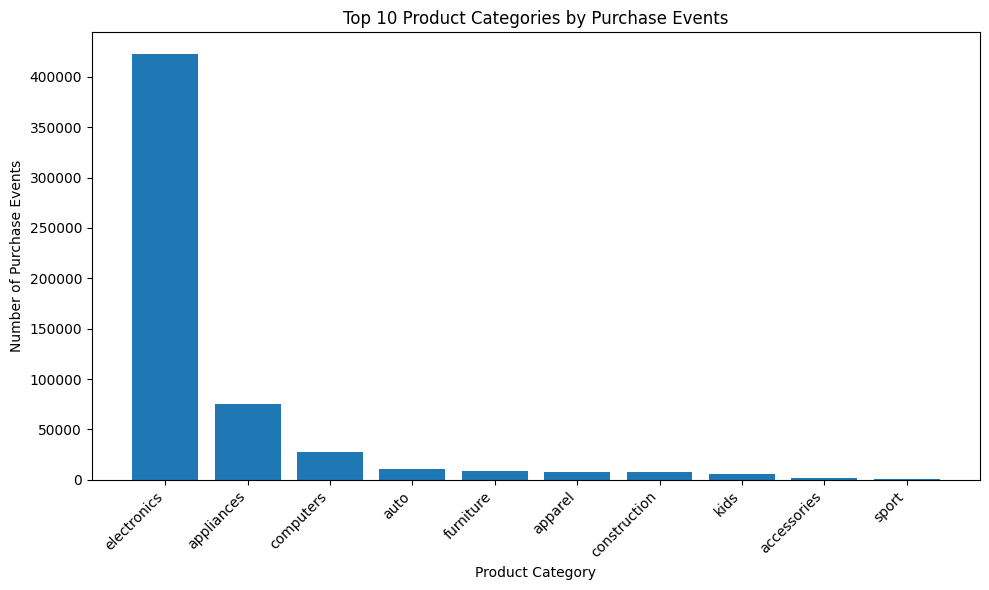

In [88]:
import matplotlib.pyplot as plt

# Keep only purchase events and exclude missing categories
category_purchases = category_summary[
    (category_summary["event_type"] == "purchase")
    & (category_summary["main_category"].notna())
].copy()

# Select the 10 categories with the most purchase events
category_purchases = category_purchases.sort_values(
    "event_count", ascending=False
).head(10)

# Create the bar chart
plt.figure(figsize=(10, 6))
plt.bar(
    category_purchases["main_category"],
    category_purchases["event_count"]
)

plt.title("Top 10 Product Categories by Purchase Events")
plt.xlabel("Product Category")
plt.ylabel("Number of Purchase Events")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

The bar chart shows that electronics recorded the highest purchase volume, with 423,028 purchase events, followed by appliances and computers. This indicates that electronics accounted for a substantial share of recorded purchase activity in the dataset. However, purchase volume should be interpreted alongside customer activity and session-level metrics, as it does not directly measure conversion performance.


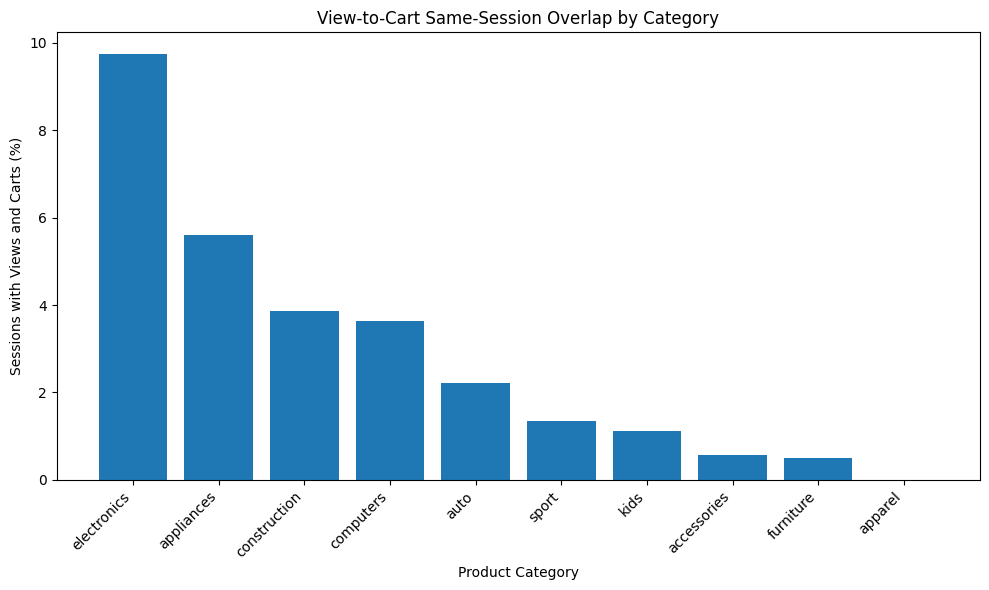

In [89]:
# Select the 10 categories with the most view sessions
top_view_categories = (
    category_conversion_table
    .sort_values("view_sessions", ascending=False)
    .head(10)
    .sort_values("view_to_cart_overlap_pct", ascending=False)
)

plt.figure(figsize=(10, 6))

plt.bar(
    top_view_categories["main_category"].fillna("Unknown"),
    top_view_categories["view_to_cart_overlap_pct"]
)

plt.title("View-to-Cart Same-Session Overlap by Category")
plt.xlabel("Product Category")
plt.ylabel("Sessions with Views and Carts (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

The view-to-cart same-session overlap chart shows that electronics had the highest overlap at approximately 9.76%, followed by appliances at 5.60% and construction at 3.87%. In contrast, furniture and apparel recorded much lower overlaps of approximately 0.49% and 0.01%, respectively. These differences suggest that the extent of cart activity within viewing sessions varies across categories. However, the results should be interpreted cautiously, particularly for apparel, which had only 21 cart sessions. The percentages represent same-session overlap rather than confirmed sequential conversion rates.


## 2.5 Price-Band Performance Analysis

In [85]:
#Count views, cart eventd and purchase by price band
price_band_events = Counter()

for chunk in pd.read_csv(
    file_path,
    chunksize=1_000_000,
    usecols=["price_band", "event_type"]
):
    counts = chunk.groupby(
        ["price_band", "event_type"],
        dropna=False
    ).size()

    price_band_events.update(counts.to_dict())

print("Total price-band/event combinations:",
      len(price_band_events))

Total price-band/event combinations: 20


In [86]:
#Create a price-band summary table
price_band_summary = pd.DataFrame(
    [
        {
            "price_band": price_band,
            "event_type": event_type,
            "event_count": count
        }
        for (price_band, event_type), count
        in price_band_events.items()
    ]
)

price_band_pivot = price_band_summary.pivot_table(
    index="price_band",
    columns="event_type",
    values="event_count",
    aggfunc="sum",
    fill_value=0
)

price_band_pivot["total_events"] = (
    price_band_pivot["view"]
    + price_band_pivot["cart"]
    + price_band_pivot["purchase"]
)

price_band_pivot["purchase_event_share_pct"] = (
    price_band_pivot["purchase"]
    / price_band_pivot["total_events"]
    * 100
)

print(
    price_band_pivot[
        ["view", "cart", "purchase", "total_events",
         "purchase_event_share_pct"]
    ].round(2)
)

event_type        view    cart  purchase  total_events  \
price_band                                               
$0–50          7690085   98616    117072       7905773   
$1,000+        2331610   66768     49404       2447782   
$100–250      12042928  360472    249314      12652714   
$250–500       7712347  202286    147781       8062414   
$500–1,000     4385982  114940     86973       4587895   
$50–100        6547924   83282     92305       6723511   
Unknown / $0     68523     150         0         68673   

event_type    purchase_event_share_pct  
price_band                              
$0–50                             1.48  
$1,000+                           2.02  
$100–250                          1.97  
$250–500                          1.83  
$500–1,000                        1.90  
$50–100                           1.37  
Unknown / $0                      0.00  


Products priced 100–250 dollars generated the most activity.

This band recorded approximately 12.65 million total events and 249,314 purchase events. It represents the largest volume of activity among the price bands.

The $1,000+ band had the highest purchase-event share.

At 2.02%, it was slightly higher than the $100–250 band at 1.97%. However, this does not prove that expensive products convert better. Purchase-event share measures the proportion of recorded events that were purchases, not the percentage of viewers who bought something.

The $50–100 band had the lowest purchase-event share among the priced bands.

Its share was 1.37%, compared with 1.48% for $0–50 products. This difference could be worth investigating, but we cannot identify its cause from these counts alone.

4Zero-priced or unknown-price records need separate treatment.

The Unknown / $0 band has 68,673 events and no purchases. We should not interpret this as evidence that free products never sell, because the band combines zero-priced products with records classified as unknown by our preprocessing.

In [87]:
#Compare cart-to-purchase session overlap by price band
price_band_sessions = {}

for chunk in pd.read_csv(
    file_path,
    chunksize=1_000_000,
    usecols=["price_band", "event_type", "user_session"]
):
    chunk = chunk.dropna(subset=["user_session"])

    for (price_band, event_type), group in chunk.groupby(
        ["price_band", "event_type"],
        dropna=False
    ):
        key = (price_band, event_type)

        if key not in price_band_sessions:
            price_band_sessions[key] = set()

        price_band_sessions[key].update(
            group["user_session"].unique()
        )

price_band_overlap_rows = []

for price_band in price_band_pivot.index:
    cart_sessions = price_band_sessions.get(
        (price_band, "cart"), set()
    )
    purchase_sessions = price_band_sessions.get(
        (price_band, "purchase"), set()
    )

    overlap = cart_sessions & purchase_sessions

    price_band_overlap_rows.append({
        "price_band": price_band,
        "cart_sessions": len(cart_sessions),
        "purchase_sessions": len(purchase_sessions),
        "cart_and_purchase_sessions": len(overlap),
        "cart_to_purchase_overlap_pct": (
            len(overlap) / len(cart_sessions) * 100
            if cart_sessions else 0
        )
    })

price_band_overlap = pd.DataFrame(price_band_overlap_rows)

print(
    price_band_overlap.sort_values(
        "cart_to_purchase_overlap_pct",
        ascending=False
    ).round(2).to_string(index=False)
)

  price_band  cart_sessions  purchase_sessions  cart_and_purchase_sessions  cart_to_purchase_overlap_pct
    $100–250         220998             219969                      118323                         53.54
  $500–1,000          77407              76435                       40023                         51.70
    $250–500         130410             130563                       67264                         51.58
     $1,000+          45449              42969                       23402                         51.49
     $50–100          54958              85018                       24471                         44.53
       $0–50          65293             105757                       26082                         39.95
Unknown / $0            102                  0                           0                          0.00


### Price-Band Analysis

Price-band analysis showed that products priced between $100 and $250 generated the highest activity, with approximately 12.65 million events and 249,314 purchase events. This band also recorded the highest cart-to-purchase same-session overlap at 53.54%, with 118,323 sessions containing both event types.

The $1,000+ price band had the highest purchase-event share at 2.02%, followed by the 100–250 band at 1.97%. However, purchase-event share is not a customer conversion rate and does not establish that higher-priced products are more likely to be purchased. The 0–50 and 50–100 bands recorded lower cart-to-purchase overlap rates of 39.95% and 44.53%, respectively. These differences may warrant further investigation into product mix and customer behaviour.

Overall, the findings suggest that the 100–250 band is an important segment for further analysis because of its high activity and purchase volume. However, same-session overlap does not confirm event order, and the combined Unknown / 0 band should be treated cautiously because it includes records with missing or zero prices.

# Business Insights and Recommendations

The analysis suggests several opportunities for an e-commerce business to improve product visibility, understand customer behaviour and strengthen data quality.

First, electronics and appliances should be prioritised for further product-level analysis because they generated substantial purchase activity. The business could identify popular products within these categories and assess whether improving product-page information, recommendations or product placement could support customer engagement.

Second, Samsung and Apple warrant further investigation because they recorded the highest purchase volumes among the named brands. Comparing their product-level activity and price ranges could help the business understand which products attract attention and generate purchase activity. However, purchase-event share should not be treated as a direct measure of customer conversion.

Third, products priced between $100 and $250 deserve further examination because this band generated the highest purchase volume and cart-to-purchase same-session overlap. The business could investigate whether selected products in this range would benefit from improved visibility or targeted promotions, while evaluating the results before expanding these initiatives.

Finally, the unusually low cart activity for apparel and Lucente highlights the need to validate event tracking and product metadata. Improving data completeness and checking event sequences would make future conversion analysis more reliable.

These recommendations should be treated as hypotheses for further investigation rather than proven interventions. A future analysis could calculate sequential session-level conversion rates and evaluate changes through controlled experiments.



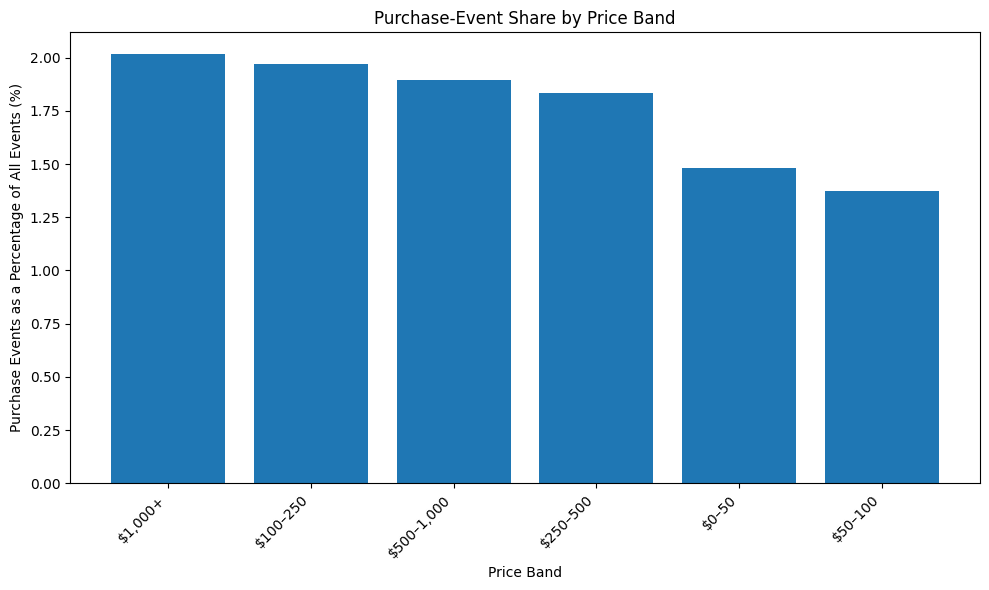

In [90]:
# Exclude Unknown / $0 from the comparison
priced_bands = price_band_pivot.drop(
    index="Unknown / $0",
    errors="ignore"
).sort_values("purchase_event_share_pct", ascending=False)

plt.figure(figsize=(10, 6))

plt.bar(
    priced_bands.index,
    priced_bands["purchase_event_share_pct"]
)

plt.title("Purchase-Event Share by Price Band")
plt.xlabel("Price Band")
plt.ylabel("Purchase Events as a Percentage of All Events (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

The purchase-event share chart shows that products priced at 1,000 or above had the highest share at approximately 2.02%, followed by the 100–250 band at 1.97%. The 50–100 band recorded the lowest share among priced products at 1.37%. Although the highest-priced band had the largest proportion of purchase events, the $100–250 band generated the greatest number of purchases. This highlights the difference between purchase-event share and purchase volume. These results are descriptive and should not be interpreted as customer conversion rates.


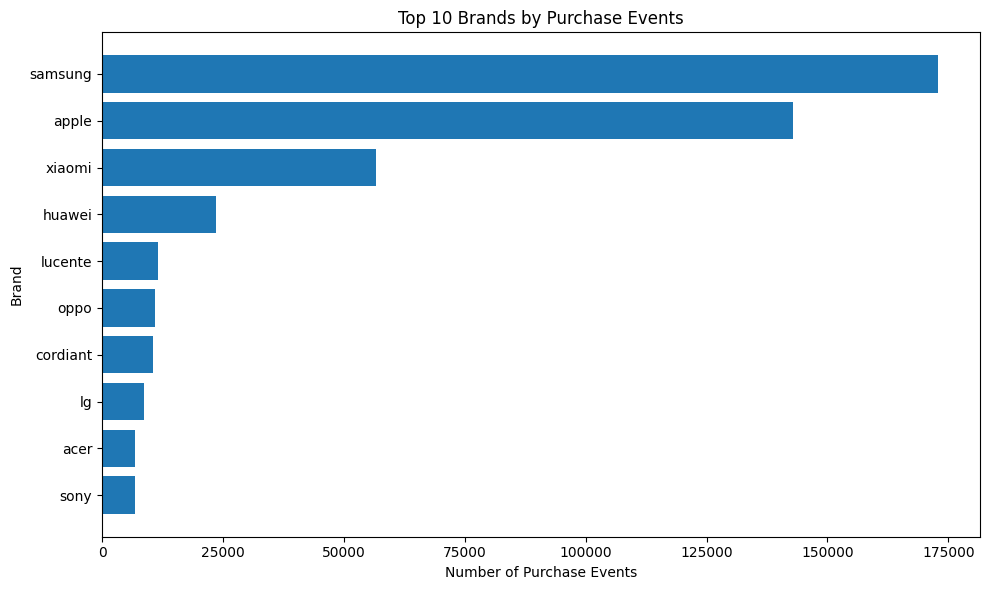

In [91]:
# Exclude missing brand information
named_brand_purchases = brand_pivot.drop(
    index="Unknown",
    errors="ignore"
)

# Select the 10 brands with the most purchase events
top_brands = named_brand_purchases.sort_values(
    "purchase",
    ascending=False
).head(10)

# Sort for a clearer chart, with the largest bar at the top
top_brands = top_brands.sort_values("purchase")

plt.figure(figsize=(10, 6))

plt.barh(
    top_brands.index,
    top_brands["purchase"]
)

plt.title("Top 10 Brands by Purchase Events")
plt.xlabel("Number of Purchase Events")
plt.ylabel("Brand")
plt.tight_layout()
plt.show()

The bar chart shows that Samsung recorded the highest purchase volume among the top 10 named brands, with 172,896 purchase events, followed by Apple with 142,873. Xiaomi ranked third with 56,616 purchase events, while Sony had the lowest volume among the brands shown, with 6,729. These findings indicate that Samsung and Apple accounted for substantial recorded purchase activity in the dataset. However, purchase volume alone does not measure conversion performance or customer loyalty.


# 4 Time-Based Customer Behaviour Analysis

In [6]:
#Count views, cart events and purchases for each hour
from collections import Counter
hourly_events = Counter()

for chunk in pd.read_csv(
    file_path,
    chunksize=1_000_000,
    usecols=["hour", "event_type"]
):
    counts = chunk.groupby(
        ["hour", "event_type"],
        dropna=False
    ).size()

    hourly_events.update(counts.to_dict())

print("Total hour-event combinations:", len(hourly_events))

Total hour-event combinations: 72


In [7]:
#Convert the hourly event counts into a DataFrame
hourly_summary = pd.DataFrame(
    [
        {
            "hour": hour,
            "event_type": event_type,
            "event_count": count
        }
        for (hour, event_type), count in hourly_events.items()
    ]
)

#Display the first few rows
hourly_summary.head(10)

,hour,event_type,event_count
0,0,cart,3982
1,0,purchase,2949
2,0,view,299874
3,1,view,545742
4,2,cart,17764
5,2,purchase,13968
6,2,view,1037315
7,3,cart,34725
8,3,purchase,29634
9,3,view,1485926


## 4.1 Busiest Hours Analysis

In [8]:
# ind the top 5 busiest hours for each event type
for event in ["view", "cart", "purchase"]:
    print(f"\nTop 5 busiest hours for {event}s:")

    top_hours = (
        hourly_summary[hourly_summary["event_type"] == event]
        .sort_values("event_count", ascending=False)
        .head(5)
    )

    print(top_hours[["hour", "event_count"]].to_string(index=False))


Top 5 busiest hours for views:
 hour  event_count
   16      2972082
   15      2892601
   17      2663340
   14      2590385
    8      2267899

Top 5 busiest hours for carts:
 hour  event_count
    9        67236
    8        67031
    7        64566
   10        63712
    6        62619

Top 5 busiest hours for purchases:
 hour  event_count
    8        55197
    9        55183
    7        53406
    6        52005
   10        51904


Views: The busiest period is in the afternoon, especially 3–5 PM.

Cart events: The busiest hours are concentrated between 6 AM and 10 AM.

Purchases: Purchases are also concentrated in the morning, particularly between 7 AM and 10 AM.

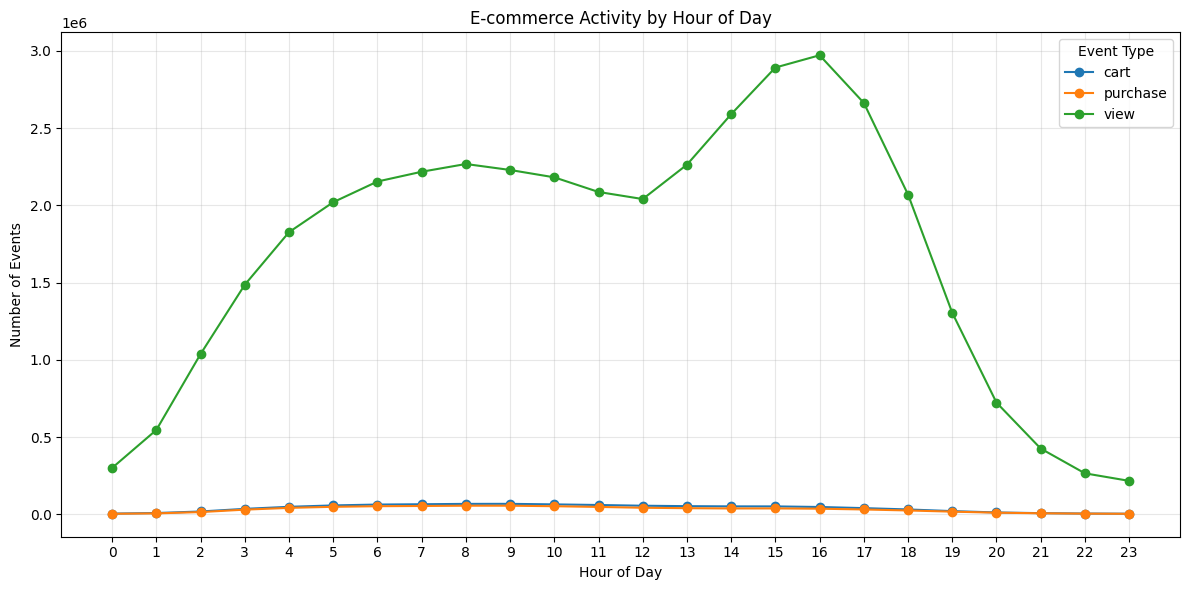

In [9]:
import matplotlib.pyplot as plt

#Reshape the data so each event type has its own column
hourly_pivot = hourly_summary.pivot(
    index="hour",
    columns="event_type",
    values="event_count"
)

#Plot hourly activity
hourly_pivot.plot(figsize=(12, 6), marker="o")

plt.title("E-commerce Activity by Hour of Day")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Events")
plt.xticks(range(24))
plt.legend(title="Event Type")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

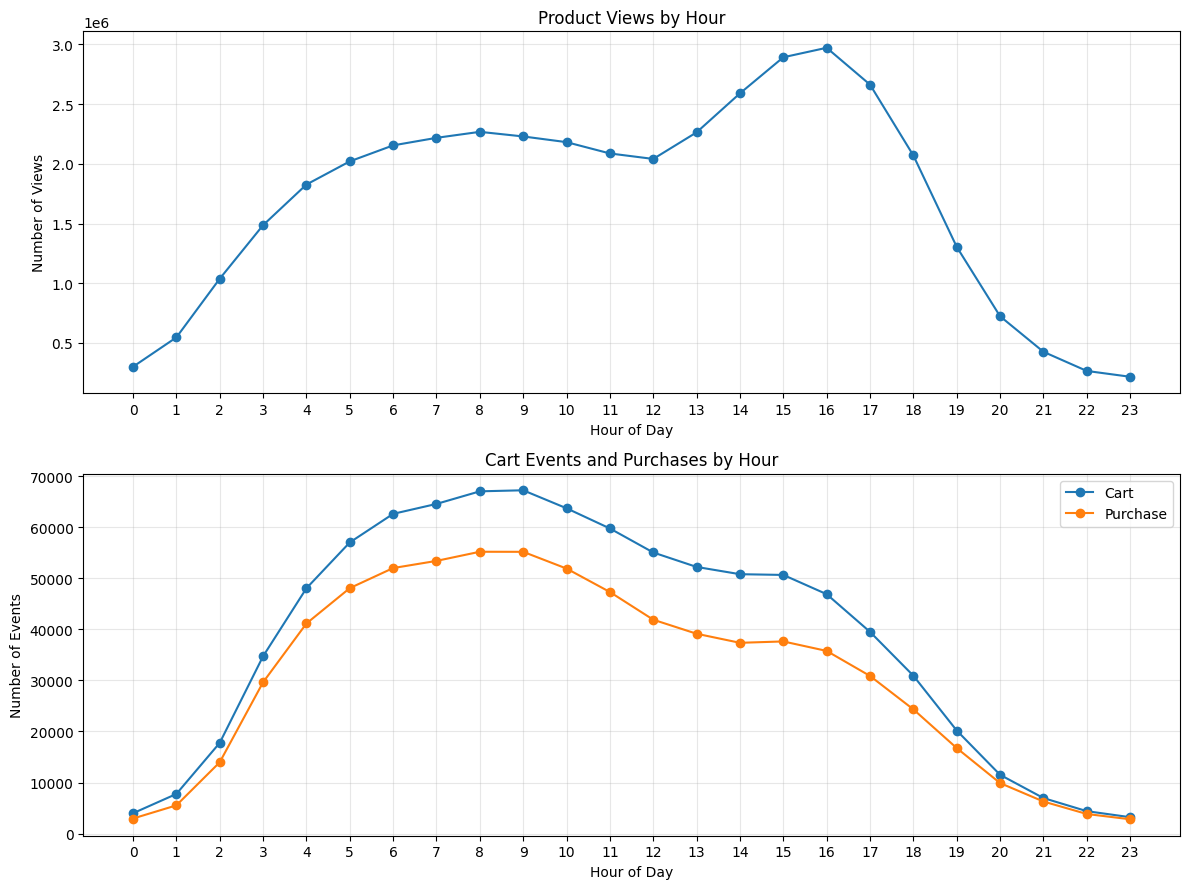

In [10]:
# Create two charts with separate scales
fig, axes = plt.subplots(2, 1, figsize=(12, 9))

# Chart 1: Views
axes[0].plot(
    hourly_pivot.index,
    hourly_pivot["view"],
    marker="o"
)
axes[0].set_title("Product Views by Hour")
axes[0].set_xlabel("Hour of Day")
axes[0].set_ylabel("Number of Views")
axes[0].set_xticks(range(24))
axes[0].grid(True, alpha=0.3)

# Chart 2: Cart events and purchases
axes[1].plot(
    hourly_pivot.index,
    hourly_pivot["cart"],
    marker="o",
    label="Cart"
)
axes[1].plot(
    hourly_pivot.index,
    hourly_pivot["purchase"],
    marker="o",
    label="Purchase"
)
axes[1].set_title("Cart Events and Purchases by Hour")
axes[1].set_xlabel("Hour of Day")
axes[1].set_ylabel("Number of Events")
axes[1].set_xticks(range(24))
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Hourly analysis revealed different activity patterns across the three event types. Product views peaked at 4 PM, with approximately 2.97 million events, while cart activity peaked at 9 AM with 67,236 events. Purchases peaked slightly earlier, at 8 AM, with 55,197 events. Cart and purchase activity generally followed similar trends, although cart events were consistently more frequent. These findings suggest that browsing and purchasing-related activities have different peak periods. However, the results represent total events across October 2019 and do not establish why these patterns occur.


## 4.2 Analyse activity by day if the week

In [11]:
#Count events for each day of the week
daily_events = Counter()

for chunk in pd.read_csv(
    file_path,
    chunksize=1_000_000,
    usecols=["day_of_week", "event_type"]
):
    counts = chunk.groupby(
        ["day_of_week", "event_type"],
        dropna=False
    ).size()

    daily_events.update(counts.to_dict())

print("Total day-event combinations:", len(daily_events))

Total day-event combinations: 21


In [12]:
#Convert daily event counts into a DataFrame
daily_summary = pd.DataFrame(
    [
        {
            "day_of_week": day,
            "event_type": event_type,
            "event_count": count
        }
        for (day, event_type), count in daily_events.items()
    ]
)

#Display the results sorted by day
daily_summary = daily_summary.sort_values(
    ["day_of_week", "event_type"]
)

daily_summary

,day_of_week,event_type,event_count
9,Friday,cart,142237
10,Friday,purchase,103044
11,Friday,view,5584378
18,Monday,cart,117423
19,Monday,purchase,96062
20,Monday,view,5108044
12,Saturday,cart,130429
13,Saturday,purchase,96177
14,Saturday,view,5380190
15,Sunday,cart,131768


In [14]:
# Create a table with one row per weekday
daily_pivot = daily_summary.pivot(
    index="day_of_week",
    columns="event_type",
    values="event_count"
)

# Arrange weekdays in calendar order
weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

daily_pivot = daily_pivot.reindex(weekday_order)

# Display the table
daily_pivot

event_type,cart,purchase,view
day_of_week,,,
Monday,117423,96062,5108044
Tuesday,139056,114510,6548319
Wednesday,134382,119159,6398991
Thursday,131219,113664,6135484
Friday,142237,103044,5584378
Saturday,130429,96177,5380190
Sunday,131768,100233,5623993


Tuesday had the highest browsing activity, with approximately 6.55 million views.

Wednesday had the highest purchase volume, with 119,159 purchase events.

Friday had the most cart events, with 142,237.

Monday had the lowest counts across all three event types.

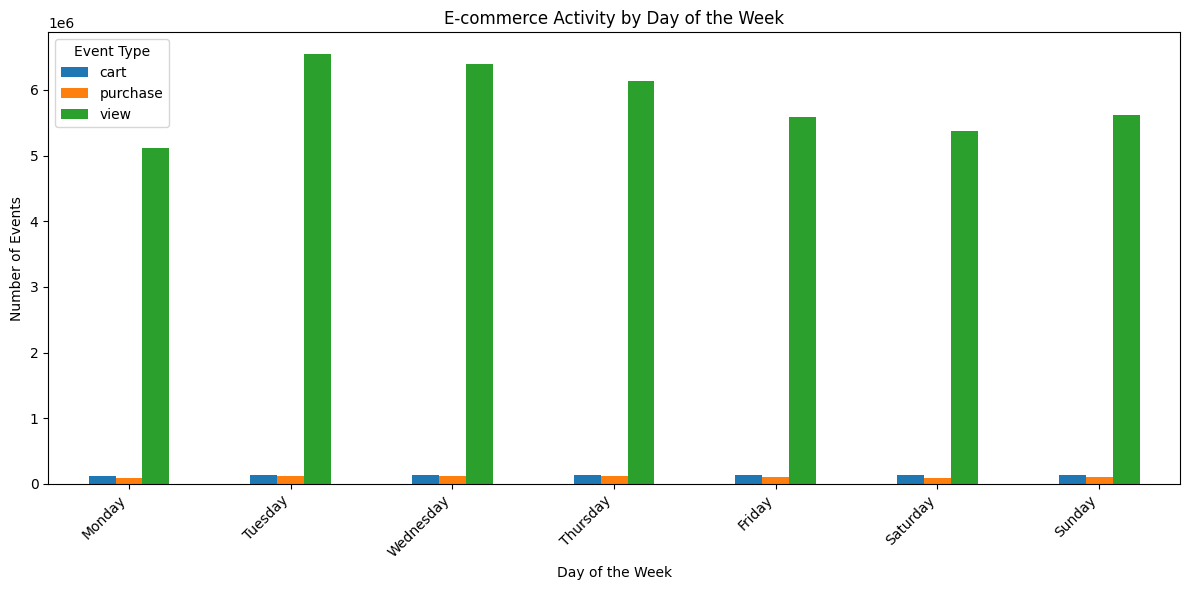

In [15]:
#Plot activity by day of the week
daily_pivot.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("E-commerce Activity by Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Number of Events")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Event Type")
plt.tight_layout()
plt.show()

Daily analysis showed that Tuesday recorded the highest number of product views, with approximately 6.55 million events, while Monday had the lowest viewing activity. Wednesday recorded the highest purchase volume at 119,159 events, and Friday had the highest number of cart events at 142,237. Although viewing activity varied across the week, cart and purchase counts were relatively consistent. These findings suggest that customer activity varies by day, but the differences are not necessarily large for cart and purchase events. As the results represent total event counts, the number of occurrences of each weekday in October should be considered when making comparisons.


Compare weekdays with weekends

In [16]:
#Count events on weekdays versus weekends
weekend_events = Counter()

for chunk in pd.read_csv(
    file_path,
    chunksize=1_000_000,
    usecols=["is_weekend", "event_type"]
):
    counts = chunk.groupby(
        ["is_weekend", "event_type"],
        dropna=False
    ).size()

    weekend_events.update(counts.to_dict())

#Convert the counts into a DataFrame
weekend_summary = pd.DataFrame(
    [
        {
            "is_weekend": is_weekend,
            "event_type": event_type,
            "event_count": count
        }
        for (is_weekend, event_type), count in weekend_events.items()
    ]
)

weekend_summary

,is_weekend,event_type,event_count
0,False,cart,664317
1,False,purchase,546439
2,False,view,29775216
3,True,cart,262197
4,True,purchase,196410
5,True,view,11004183


## 4.3 Weekend vs Weekday

In [17]:
#Give the weekday/weekend labels readable names
weekend_summary["day_group"] = weekend_summary["is_weekend"].map({
    False: "Weekday",
    True: "Weekend"
})

#Arrange event types into separate columns
weekend_pivot = weekend_summary.pivot(
    index="day_group",
    columns="event_type",
    values="event_count"
)

weekend_pivot

event_type,cart,purchase,view
day_group,,,
Weekday,664317,546439,29775216
Weekend,262197,196410,11004183


In [18]:
# Calculate average events per day
weekday_days = 23
weekend_days = 8

daily_average = weekend_pivot.copy()

daily_average.loc["Weekday"] = (
    weekend_pivot.loc["Weekday"] / weekday_days
)

daily_average.loc["Weekend"] = (
    weekend_pivot.loc["Weekend"] / weekend_days
)

daily_average

/tmp/ipykernel_2074/3046263487.py:7: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '28883.347826086956' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  daily_average.loc["Weekday"] = (
/tmp/ipykernel_2074/3046263487.py:7: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '23758.217391304348' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  daily_average.loc["Weekday"] = (
/tmp/ipykernel_2074/3046263487.py:7: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '1294574.608695652' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  daily_average.loc["Weekday"] = (


event_type,cart,purchase,view
day_group,,,
Weekday,28883.347826,23758.217391,1.294575e+06
Weekend,32774.625000,24551.250000,1.375523e+06


The weekday-versus-weekend analysis showed that average daily activity was higher on weekends across all three event types. Weekends recorded approximately 1.38 million views, 32,775 cart events and 24,551 purchase events per day, compared with 1.29 million views, 28,883 cart events and 23,758 purchase events on weekdays. This represents approximately 6.3% more views, 13.5% more cart events and 3.3% more purchases per weekend day. The findings suggest that customers were more active on weekends, particularly when adding products to carts. However, the relatively small difference in purchase activity indicates that higher browsing and cart activity does not necessarily translate into a comparable increase in purchases.


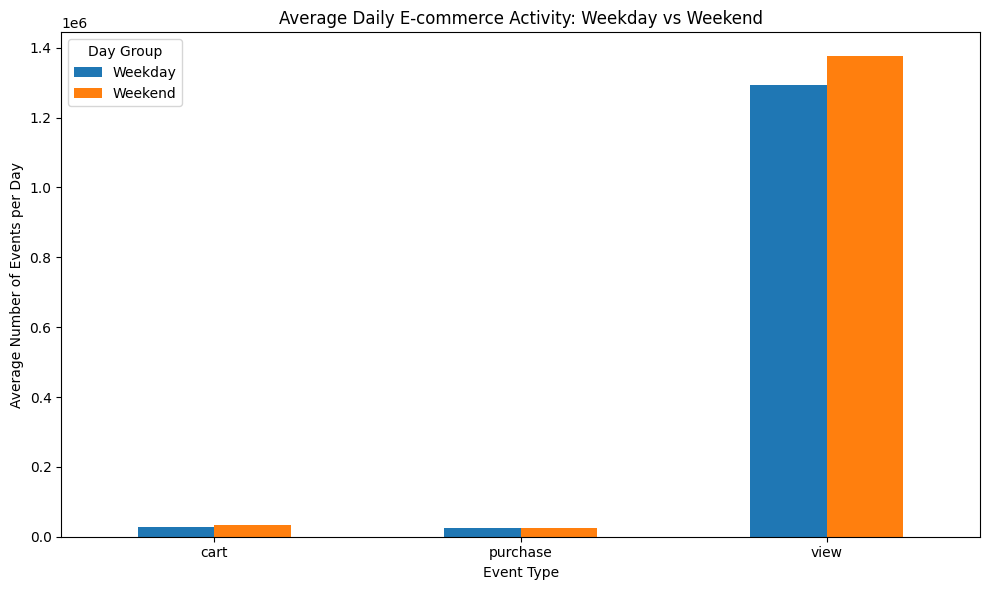

In [19]:
#Plot average daily activity for weekdays and weekends
daily_average.T.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Average Daily E-commerce Activity: Weekday vs Weekend")
plt.xlabel("Event Type")
plt.ylabel("Average Number of Events per Day")
plt.xticks(rotation=0)
plt.legend(title="Day Group")
plt.tight_layout()
plt.show()

The chart shows that average daily activity was generally higher on weekends than on weekdays. Product views were the highest event type, averaging approximately 1.38 million per weekend day compared with 1.29 million per weekday. Cart activity was also higher on weekends, while purchase activity was relatively similar between the two groups. This suggests that customers may browse and add products to their carts more frequently on weekends, although the difference in purchases is smaller. The business could investigate whether weekend promotions or targeted product recommendations improve purchasing outcomes, but further analysis would be needed to establish their effectiveness.


## Business Insights and Recommendations

The time-based analysis revealed several patterns in customer activity across October 2019. Product views peaked at 4 PM, while cart and purchase activity were concentrated in the morning, particularly between 6 AM and 10 AM. This suggests that browsing and purchasing-related activities have different peak periods. The business could investigate whether adjusting the timing of promotions or product recommendations would help customers progress from browsing to purchasing.

Daily analysis showed that Tuesday recorded the highest number of views, Wednesday had the highest purchase volume, and Friday had the most cart events. Monday recorded the lowest counts across all three event types. However, these are total event counts, so differences in the number of each weekday during October should be considered.

The weekday-versus-weekend comparison showed that average daily activity was higher on weekends. Weekend days recorded approximately 6.3% more views, 13.5% more cart events and 3.3% more purchases than weekdays. This suggests that weekends may be a useful period for testing targeted promotions or product recommendations, particularly because cart activity was noticeably higher.

Overall, these findings can help an e-commerce business identify periods for further investigation and potential marketing opportunities. However, the analysis is descriptive and does not establish the causes of these patterns. Future work could examine session-level event sequences and test promotional changes through controlled experiments to determine whether they improve purchase outcomes.


# 5 Customer Session and Conversion Analysis

## 5.1 Session Activity Overview

In [21]:
# Count events for each session and event type
session_event_counts = Counter()

for chunk in pd.read_csv(
    file_path,
    chunksize=1_000_000,
    usecols=["user_session", "event_type"]
):
    counts = chunk.groupby(
        ["user_session", "event_type"]
    ).size()

    session_event_counts.update(counts.to_dict())

print("Session-event combinations:", len(session_event_counts))

Session-event combinations: 10445310


In [22]:
# Convert session-event counts into a DataFrame
session_activity = pd.DataFrame(
    [
        {
            "user_session": session,
            "event_type": event_type,
            "event_count": count
        }
        for (session, event_type), count in session_event_counts.items()
    ]
)

# Summarise event counts per session for each event type
session_activity.groupby("event_type")["event_count"].describe()

,count,mean,std,min,25%,50%,75%,max
event_type,,,,,,,,
cart,573097.0,1.616679,1.701198,1.0,1.0,1.0,2.0,118.0
purchase,629560.0,1.179949,0.600796,1.0,1.0,1.0,1.0,48.0
view,9242653.0,4.412088,6.660797,1.0,1.0,2.0,5.0,1158.0


Views: A typical session containing views had 2 view events, although the average was 4.41. Some sessions had very large numbers of views, which raised the average.

Cart events: The median was 1 cart event per session, meaning at least half of cart-containing sessions had only one cart event.

Purchases: The median was also 1 purchase event per session, and the average was 1.18. Most purchase-containing sessions therefore had relatively few purchase events.

Outliers: Some sessions had unusually high event counts, particularly views, with a maximum of 1,158. These may represent unusually long or highly active sessions, so we should avoid assuming every session behaves like the average.

<Figure size 1000x600 with 0 Axes>

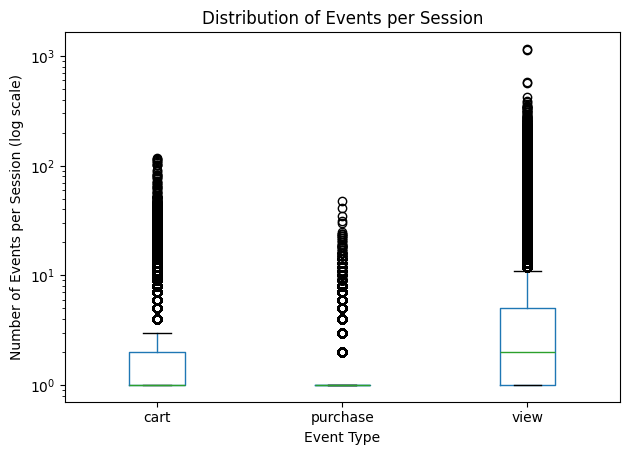

In [23]:
import matplotlib.pyplot as plt

# Create a box plot of events per session
plt.figure(figsize=(10, 6))

session_activity.boxplot(
    column="event_count",
    by="event_type",
    grid=False
)

plt.yscale("log")
plt.title("Distribution of Events per Session")
plt.suptitle("")
plt.xlabel("Event Type")
plt.ylabel("Number of Events per Session (log scale)")
plt.tight_layout()
plt.show()

The box plot shows that event counts vary across sessions. View activity had the widest distribution and the highest outliers, with some sessions recording substantially more views than typical sessions. Cart activity was concentrated at lower event counts, while purchase activity was particularly concentrated around one purchase event per session. These patterns suggest that most sessions contain relatively few interactions of each type, although a small number of highly active sessions increase the overall range. The logarithmic scale was used to make differences among typical sessions easier to observe despite the presence of extreme values.


### 5.1.1 Examine sessions with different event types

In [24]:
# Identify unique sessions containing each event type
view_sessions = set(
    session_activity.loc[
        session_activity["event_type"] == "view",
        "user_session"
    ]
)

cart_sessions = set(
    session_activity.loc[
        session_activity["event_type"] == "cart",
        "user_session"
    ]
)

purchase_sessions = set(
    session_activity.loc[
        session_activity["event_type"] == "purchase",
        "user_session"
    ]
)

print("Sessions with views:", len(view_sessions))
print("Sessions with cart events:", len(cart_sessions))
print("Sessions with purchases:", len(purchase_sessions))
print("Sessions with all three:", len(
    view_sessions & cart_sessions & purchase_sessions
))

Sessions with views: 9242653
Sessions with cart events: 573097
Sessions with purchases: 629560
Sessions with all three: 291500


In [25]:
# Calculate same-session overlap percentages
view_and_cart = view_sessions & cart_sessions
cart_and_purchase = cart_sessions & purchase_sessions
view_and_purchase = view_sessions & purchase_sessions
all_three = view_sessions & cart_sessions & purchase_sessions

print(
    "View and cart overlap:",
    round(len(view_and_cart) / len(view_sessions) * 100, 2),
    "%"
)

print(
    "Cart and purchase overlap:",
    round(len(cart_and_purchase) / len(cart_sessions) * 100, 2),
    "%"
)

print(
    "View and purchase overlap:",
    round(len(view_and_purchase) / len(view_sessions) * 100, 2),
    "%"
)

print(
    "All three event types:",
    round(len(all_three) / len(view_sessions) * 100, 2),
    "% of view sessions"
)

View and cart overlap: 6.19 %
Cart and purchase overlap: 50.93 %
View and purchase overlap: 6.8 %
All three event types: 3.15 % of view sessions


Session-level analysis found that 6.19% of sessions containing views also contained cart events, while 50.93% of sessions containing cart events also contained purchases. Additionally, 6.80% of view sessions contained purchase events, and 3.15% of view sessions contained all three event types. These findings suggest that cart and purchase activity frequently overlap within the same session,


## 5.2 Sequential Customer Journeys

In [26]:
# Store the earliest timestamp for each event type in each session
first_event_times = {}

for chunk in pd.read_csv(
    file_path,
    chunksize=1_000_000,
    usecols=["user_session", "event_type", "event_time"]
):
    chunk["event_time"] = pd.to_datetime(
        chunk["event_time"],
        utc=True
    )

    chunk = chunk[
        chunk["event_type"].isin(["view", "cart", "purchase"])
    ]

    earliest = chunk.groupby(
        ["user_session", "event_type"]
    )["event_time"].min()

    for (session, event), timestamp in earliest.items():
        key = (session, event)

        if (
            key not in first_event_times
            or timestamp < first_event_times[key]
        ):
            first_event_times[key] = timestamp

print("Session-event timestamps stored:", len(first_event_times))

Session-event timestamps stored: 10445310


In [27]:
# Count sessions that follow the expected event order
ordered_journeys = 0
all_three_sessions = 0

for session in all_three:
    view_time = first_event_times.get((session, "view"))
    cart_time = first_event_times.get((session, "cart"))
    purchase_time = first_event_times.get((session, "purchase"))

    if view_time is not None and cart_time is not None and purchase_time is not None:
        all_three_sessions += 1

        if view_time < cart_time < purchase_time:
            ordered_journeys += 1

print("Sessions containing all three event types:", all_three_sessions)
print("Sessions following view → cart → purchase:", ordered_journeys)

print(
    "Percentage following expected order:",
    round(ordered_journeys / all_three_sessions * 100, 2),
    "%"
)

Sessions containing all three event types: 291500
Sessions following view → cart → purchase: 278727
Percentage following expected order: 95.62 %


Chronological session analysis identified 291,500 sessions containing views, cart events and purchases. Of these, 278,727 sessions (95.62%) followed the expected order based on the earliest recorded timestamp for each event type: view → cart → purchase. This indicates that most sessions containing all three event types followed the expected sequence. However, the result is conditional on sessions already containing all three event types and should not be interpreted as an overall conversion rate. The analysis also uses the earliest timestamp for each event type rather than examining every individual interaction.


In [28]:
# Identify sessions without the next event type
views_without_cart = view_sessions - cart_sessions
carts_without_purchase = cart_sessions - purchase_sessions
views_without_purchase = view_sessions - purchase_sessions

# Print the number of sessions
print("View sessions without cart:", len(views_without_cart))
print("Cart sessions without purchase:", len(carts_without_purchase))
print("View sessions without purchase:", len(views_without_purchase))

View sessions without cart: 8670746
Cart sessions without purchase: 281236
View sessions without purchase: 8614032


In [29]:
# Calculate same-session drop-off percentages
view_no_cart_pct = (
    len(views_without_cart) / len(view_sessions) * 100
)

cart_no_purchase_pct = (
    len(carts_without_purchase) / len(cart_sessions) * 100
)

view_no_purchase_pct = (
    len(views_without_purchase) / len(view_sessions) * 100
)

print(
    "View sessions without cart:",
    round(view_no_cart_pct, 2), "%"
)

print(
    "Cart sessions without purchase:",
    round(cart_no_purchase_pct, 2), "%"
)

print(
    "View sessions without purchase:",
    round(view_no_purchase_pct, 2), "%"
)

View sessions without cart: 93.81 %
Cart sessions without purchase: 49.07 %
View sessions without purchase: 93.2 %


Same-session drop-off analysis showed that 93.81% of sessions containing views had no cart events, while 49.07% of cart-containing sessions had no purchase events. Similarly, 93.20% of viewing sessions did not contain a purchase event. These findings suggest that most browsing sessions did not progress to cart activity within the same session, while approximately half of cart-containing sessions also contained purchases. The results highlight potential opportunities to investigate product-page engagement and the checkout journey. However, they do not confirm that customers abandoned their purchases entirely, as subsequent activity may have occurred in another session.


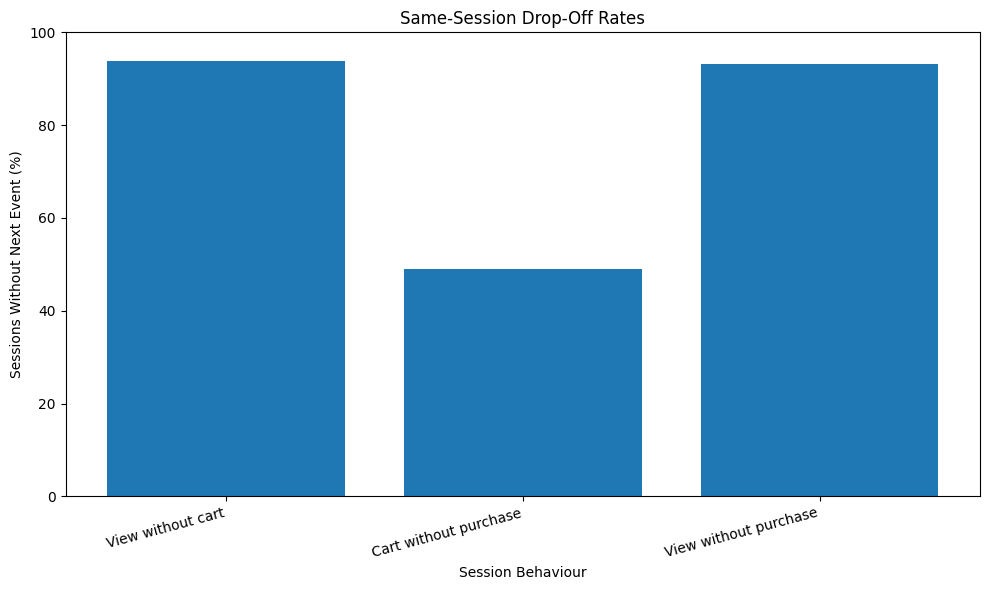

In [30]:
#Plot same-session drop-off percentages
dropoff_data = pd.Series({
    "View without cart": view_no_cart_pct,
    "Cart without purchase": cart_no_purchase_pct,
    "View without purchase": view_no_purchase_pct
})

plt.figure(figsize=(10, 6))
plt.bar(dropoff_data.index, dropoff_data.values)

plt.title("Same-Session Drop-Off Rates")
plt.xlabel("Session Behaviour")
plt.ylabel("Sessions Without Next Event (%)")
plt.ylim(0, 100)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

The bar chart shows that view sessions without cart events and view sessions without purchases had the highest same-session drop-off rates, at 93.81% and 93.20%, respectively. In comparison, 49.07% of cart-containing sessions did not contain a purchase event. This indicates that browsing sessions frequently ended without cart or purchase activity, while cart-containing sessions more often overlapped with purchases. The findings suggest that the transition from product viewing to cart activity may warrant further investigation. However, these results reflect same-session behaviour and do not confirm permanent customer abandonment.

## 5.3 Customer Session and Conversion Analysis: Insights and Recommendations

The session-level analysis revealed that customer activity varied considerably across sessions. Viewing sessions contained an average of 4.41 view events, while cart-containing sessions averaged 1.62 cart events and purchase-containing sessions averaged 1.18 purchase events. The distributions were concentrated at relatively low counts, although a small number of highly active sessions produced extreme values.

Same-session overlap analysis found that 6.19% of viewing sessions also contained cart events, while 50.93% of cart-containing sessions also contained purchases. Among sessions containing all three event types, 95.62% followed the expected view-to-cart-to-purchase order based on the earliest recorded timestamp for each event type.

Drop-off analysis showed that 93.81% of viewing sessions had no cart events and 49.07% of cart-containing sessions had no purchases within the same session. These results suggest that the transition from viewing to cart activity is a useful area for further investigation.

The business could examine product-page usability, product information, pricing and recommendations to understand why viewing sessions frequently lack cart activity. It could also investigate the checkout experience for sessions containing carts but no purchases. These should be treated as hypotheses rather than proven causes. Future analysis could examine individual customer journeys across sessions and use controlled experiments to assess whether proposed improvements increase purchases.


# 6 Customer Behaviour Segmentation

In [31]:
# Check whether the required columns are available
print("User ID available:", "user_id" in pd.read_csv(file_path, nrows=0).columns)
print("Event type available:", "event_type" in pd.read_csv(file_path, nrows=0).columns)
print("Session ID available:", "user_session" in pd.read_csv(file_path, nrows=0).columns)

User ID available: True
Event type available: True
Session ID available: True


## 6.1 Customer Activity Analysis

In [32]:
from collections import defaultdict

# Store activity statistics for each customer
customer_activity = defaultdict(lambda: {
    "views": 0,
    "carts": 0,
    "purchases": 0,
    "sessions": set()
})

# Read the dataset in chunks
for chunk in pd.read_csv(
    file_path,
    usecols=["user_id", "event_type", "user_session"],
    chunksize=1_000_000
):
    # Count each event type for every customer
    for event_type, column in [
        ("view", "views"),
        ("cart", "carts"),
        ("purchase", "purchases")
    ]:
        counts = (
            chunk.loc[chunk["event_type"] == event_type]
            .groupby("user_id")
            .size()
        )

        for user_id, count in counts.items():
            customer_activity[user_id][column] += count

    # Record each customer's sessions
    sessions = chunk.dropna(subset=["user_id", "user_session"])

    for user_id, session_id in zip(
        sessions["user_id"], sessions["user_session"]
    ):
        customer_activity[user_id]["sessions"].add(session_id)

print("Number of customers analysed:", len(customer_activity))

Number of customers analysed: 3022290


In [33]:
# Convert the customer activity dictionary into a DataFrame
customer_summary = pd.DataFrame([
    {
        "user_id": user_id,
        "views": data["views"],
        "carts": data["carts"],
        "purchases": data["purchases"],
        "unique_sessions": len(data["sessions"])
    }
    for user_id, data in customer_activity.items()
])

# Calculate total recorded interactions
customer_summary["total_events"] = (
    customer_summary["views"]
    + customer_summary["carts"]
    + customer_summary["purchases"]
)

# Display the first five customers
customer_summary.head()

,user_id,views,carts,purchases,unique_sessions,total_events
0,244951053,15,0,0,7,15
1,295655799,1,0,0,1,1
2,306441847,9,0,0,3,9
3,315309190,25,0,0,5,25
4,315805600,9,0,0,3,9


In [34]:
# Check the session count distribution
print("Customers with at least one session:",
      (customer_summary["unique_sessions"] > 0).sum())

print("Customers with zero sessions:",
      (customer_summary["unique_sessions"] == 0).sum())

print("\nSession count summary:")
print(customer_summary["unique_sessions"].describe())

Customers with at least one session: 3022290
Customers with zero sessions: 0

Session count summary:
count    3.022290e+06
mean     3.058863e+00
std      6.757155e+00
min      1.000000e+00
25%      1.000000e+00
50%      2.000000e+00
75%      3.000000e+00
max      7.400000e+03
Name: unique_sessions, dtype: float64


In [35]:
# Summarise customer activity
activity_stats = customer_summary[
    ["views", "carts", "purchases", "total_events"]
].describe()

activity_stats

,views,carts,purchases,total_events
count,3.022290e+06,3.022290e+06,3.022290e+06,3.022290e+06
mean,1.349288e+01,3.065603e-01,2.457901e-01,1.404523e+01
std,3.185573e+01,1.623813e+00,1.409521e+00,3.277411e+01
min,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
25%,2.000000e+00,0.000000e+00,0.000000e+00,2.000000e+00
50%,4.000000e+00,0.000000e+00,0.000000e+00,4.000000e+00
75%,1.300000e+01,0.000000e+00,0.000000e+00,1.300000e+01
max,7.436000e+03,4.940000e+02,3.220000e+02,7.436000e+03


In [36]:
# Assign each customer to a behaviour segment
conditions = [
    customer_summary["purchases"] > 0,
    (customer_summary["carts"] > 0) &
    (customer_summary["purchases"] == 0),
    (customer_summary["views"] > 0) &
    (customer_summary["carts"] == 0) &
    (customer_summary["purchases"] == 0)
]

segments = [
    "Purchasers",
    "Cart users (no purchase)",
    "Browsers only"
]

customer_summary["segment"] = "Other activity"

customer_summary.loc[conditions[0], "segment"] = segments[0]
customer_summary.loc[conditions[1], "segment"] = segments[1]
customer_summary.loc[conditions[2], "segment"] = segments[2]

# Count customers in each segment
segment_summary = (
    customer_summary["segment"]
    .value_counts()
    .rename_axis("segment")
    .reset_index(name="customers")
)

segment_summary["percentage"] = (
    segment_summary["customers"]
    / len(customer_summary) * 100
).round(2)

segment_summary

,segment,customers,percentage
0,Browsers only,2540832,84.07
1,Purchasers,347118,11.49
2,Cart users (no purchase),134340,4.44


The largest opportunity may be converting browsers into shoppers. Since 84.07% of customers recorded only views, the business could investigate product-page information, recommendations and promotional offers.

Cart users may need help completing purchases. The business could investigate checkout friction, delivery costs and payment options before testing interventions.

Purchasers could be analysed further. Understanding the products and price ranges they buy may help identify opportunities for cross-selling and repeat engagement.

In [37]:
# Compare average activity across customer segments
segment_activity = (
    customer_summary
    .groupby("segment")[
        ["views", "carts", "purchases",
         "unique_sessions", "total_events"]
    ]
    .mean()
    .round(2)
    .sort_values("purchases", ascending=False)
)

segment_activity

,views,carts,purchases,unique_sessions,total_events
segment,,,,,
Purchasers,36.72,1.97,2.14,7.13,40.83
Browsers only,9.45,0.00,0.00,2.36,9.45
Cart users (no purchase),29.91,1.80,0.00,5.79,31.71


Customer segmentation identified three main behaviour groups: browsers only (84.07%), purchasers (11.49%) and cart users without purchases (4.44%). Purchasers recorded the highest average activity, with 36.72 views and 7.13 sessions per customer, compared with 9.45 views and 2.36 sessions among browsers. Cart users also showed relatively high engagement, averaging 29.91 views and 1.80 cart events, despite recording no purchases during the observation period. These findings suggest that customer engagement differs across behaviour segments and that browsers and cart users may represent opportunities for further investigation. However, the analysis covers only October 2019 and does not establish whether customers purchased outside this period.

## 6.2 Customer purchasing behaviour Analysis

In [38]:
# Group customers based on whether they recorded a purchase
customer_summary["purchase_status"] = (
    customer_summary["purchases"] > 0
).map({
    True: "Purchased",
    False: "No purchase recorded"
})

# Count customers in each group
purchase_group_counts = (
    customer_summary["purchase_status"]
    .value_counts()
    .rename_axis("purchase_status")
    .reset_index(name="customers")
)

# Calculate the percentage of customers in each group
purchase_group_counts["percentage"] = (
    purchase_group_counts["customers"]
    / len(customer_summary) * 100
).round(2)

purchase_group_counts

,purchase_status,customers,percentage
0,No purchase recorded,2675172,88.51
1,Purchased,347118,11.49


In [39]:
# Compare average activity by purchase status
purchase_activity_comparison = (
    customer_summary
    .groupby("purchase_status")[
        ["views", "carts", "purchases",
         "unique_sessions", "total_events"]
    ]
    .mean()
    .round(2)
)

purchase_activity_comparison

,views,carts,purchases,unique_sessions,total_events
purchase_status,,,,,
No purchase recorded,10.48,0.09,0.00,2.53,10.57
Purchased,36.72,1.97,2.14,7.13,40.83


A comparison of customers by purchase status revealed clear differences in recorded activity. Customers who made at least one purchase averaged 36.72 product views, 1.97 cart events and 7.13 unique sessions, compared with 10.48 views, 0.09 cart events and 2.53 sessions among customers without recorded purchases. Purchasers also generated an average of 40.83 total events, substantially higher than the 10.57 events recorded by the other group. These findings suggest that greater customer engagement is associated with purchasing behaviour. However, the analysis is descriptive and does not establish causation. Furthermore, customers without recorded purchases may have purchased outside the October 2019 observation period.


In [40]:
# Group customers by number of unique sessions
customer_summary["session_group"] = pd.cut(
    customer_summary["unique_sessions"],
    bins=[0, 1, 2, 3, 5, 10, float("inf")],
    labels=[
        "1 session",
        "2 sessions",
        "3 sessions",
        "4–5 sessions",
        "6–10 sessions",
        "More than 10 sessions"
    ]
)

# Calculate the purchase rate for each session group
session_purchase_analysis = (
    customer_summary
    .groupby("session_group", observed=False)
    .agg(
        customers=("user_id", "count"),
        purchasers=("purchases", lambda x: (x > 0).sum())
    )
)

session_purchase_analysis["purchase_rate_pct"] = (
    session_purchase_analysis["purchasers"]
    / session_purchase_analysis["customers"] * 100
).round(2)

session_purchase_analysis

,customers,purchasers,purchase_rate_pct
session_group,,,
1 session,1475463,58734,3.98
2 sessions,565518,47341,8.37
3 sessions,294259,38653,13.14
4–5 sessions,296857,56660,19.09
6–10 sessions,251193,76523,30.46
More than 10 sessions,139000,69207,49.79


The analysis revealed a positive association between the number of unique sessions and purchase incidence. Among customers with one session, 3.98% recorded at least one purchase, compared with 30.46% among customers with six to ten sessions. This increased to 49.79% for customers with more than ten sessions. The consistent upward pattern suggests that customers with more frequent platform activity were more likely to purchase during October 2019. From a business perspective, this relationship may justify investigating customer re-engagement strategies. However, the findings do not establish causation, as customers who already intend to purchase may also visit the platform more frequently.


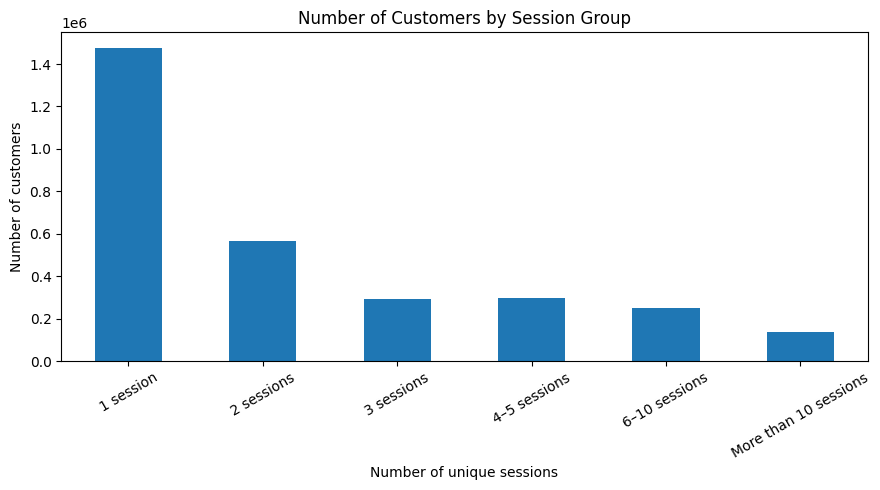

In [41]:
# Plot the number of customers in each session group
session_purchase_analysis["customers"].plot(
    kind="bar",
    figsize=(9, 5),
    title="Number of Customers by Session Group",
    xlabel="Number of unique sessions",
    ylabel="Number of customers",
    rot=30
)

plt.tight_layout()
plt.show()

The distribution of customers across session groups showed that the largest group consisted of customers with one recorded session, at approximately 1.48 million. In contrast, only 139,000 customers had more than ten sessions. Although customers with more than ten sessions showed the highest purchase incidence, this group was considerably smaller than the one-session group. These findings highlight the importance of considering both customer activity and segment size when planning engagement strategies. For example, encouraging first-time visitors to return may be worth investigating, while frequent visitors may be suitable for targeted product recommendations.

## 6.3 Customer spending patterns

In [42]:
# Count purchase events and collect their prices
purchase_prices = []

for chunk in pd.read_csv(
    file_path,
    usecols=["event_type", "price"],
    chunksize=1_000_000
):
    # Keep only purchase events with valid, positive prices
    purchases = chunk[
        (chunk["event_type"] == "purchase") &
        (chunk["price"].notna()) &
        (chunk["price"] > 0)
    ]

    purchase_prices.extend(purchases["price"].tolist())

print("Purchase events with valid prices:", len(purchase_prices))
print("Minimum purchase-event price:", round(min(purchase_prices), 2))
print("Maximum purchase-event price:", round(max(purchase_prices), 2))

Purchase events with valid prices: 742849
Minimum purchase-event price: 0.77
Maximum purchase-event price: 2574.07


In [43]:
# Summarise prices associated with purchase events
purchase_price_summary = pd.Series(purchase_prices).describe()

print(purchase_price_summary.round(2))
print("\nMedian purchase-event price:",
      round(pd.Series(purchase_prices).median(), 2))

count    742849.00
mean        309.56
std         348.87
min           0.77
25%          87.49
50%         179.84
75%         375.21
max        2574.07
dtype: float64

Median purchase-event price: 179.84


Analysis of 742,849 purchase events with valid prices found an average price of 309.56 and a median price of 179.84. The average was substantially higher than the median, suggesting that higher-priced products influenced the overall average. The middle 50% of purchase-event prices ranged from 87.49 to 375.21, indicating considerable variation in product prices. These findings suggest that purchases occurred across a broad price range. However, the recorded prices represent individual purchase events rather than confirmed order totals or actual customer expenditure.


In [44]:
# Assign each purchase event to a price band
price_bins = [0, 50, 100, 250, 500, 1000, float("inf")]

price_labels = [
    "$0–50",
    "$50–100",
    "$100–250",
    "$250–500",
    "$500–1,000",
    "$1,000+"
]

purchase_price_bands = pd.cut(
    pd.Series(purchase_prices),
    bins=price_bins,
    labels=price_labels,
    right=True,
    include_lowest=True
)

# Count purchase events in each band
purchase_band_counts = (
    purchase_price_bands
    .value_counts()
    .reindex(price_labels, fill_value=0)
    .rename_axis("price_band")
    .reset_index(name="purchase_events")
)

purchase_band_counts["percentage"] = (
    purchase_band_counts["purchase_events"]
    / len(purchase_prices) * 100
).round(2)

purchase_band_counts

,price_band,purchase_events,percentage
0,$0–50,117072,15.76
1,$50–100,92305,12.43
2,$100–250,249314,33.56
3,$250–500,147781,19.89
4,"$500–1,000",86973,11.71
5,"$1,000+",49404,6.65


The price-band analysis showed that products priced between $100 and $250 accounted for the largest share of purchase events, with 249,314 events (33.56%). The $250–500 band contributed a further 147,781 events (19.89%), meaning that approximately 53.45% of purchase events occurred within the $100–500 range. In comparison, products priced above $1,000 accounted for 6.65% of purchase events. These findings indicate that mid-priced products represented a substantial proportion of recorded purchasing activity. However, purchase-event counts do not directly measure revenue, profitability or customer spending per order.


In [45]:
# Re-read purchase records with customer IDs and prices
band_customer_counts = {label: set() for label in price_labels}

for chunk in pd.read_csv(
    file_path,
    usecols=["user_id", "event_type", "price"],
    chunksize=1_000_000
):
    purchases = chunk[
        (chunk["event_type"] == "purchase") &
        (chunk["price"].notna()) &
        (chunk["price"] > 0)
    ]

    # Assign each purchase event to a price band
    bands = pd.cut(
        purchases["price"],
        bins=price_bins,
        labels=price_labels,
        right=True,
        include_lowest=True
    )

    # Record unique customers in each band
    for label in price_labels:
        users = purchases.loc[bands == label, "user_id"].dropna()
        band_customer_counts[label].update(users)

# Summarise unique customers by price band
band_customer_summary = pd.DataFrame({
    "price_band": price_labels,
    "unique_customers": [
        len(band_customer_counts[label])
        for label in price_labels
    ]
})

band_customer_summary

,price_band,unique_customers
0,$0–50,76448
1,$50–100,63872
2,$100–250,142729
3,$250–500,84983
4,"$500–1,000",46513
5,"$1,000+",25083


An analysis of distinct purchasing customers by price band found that the 100–250 range had the highest customer count, with 142,729 customers. The 250–500 range followed with 84,983 customers, while the $1,000+ range had the fewest, at 25,083 customers. The number of distinct purchasing customers generally declined across the higher price bands. Together with the purchase-event analysis, these findings indicate that mid-priced products accounted for a substantial share of recorded purchasing activity and attracted the largest number of purchasing customers. However, the results do not establish customer price preferences or product profitability.


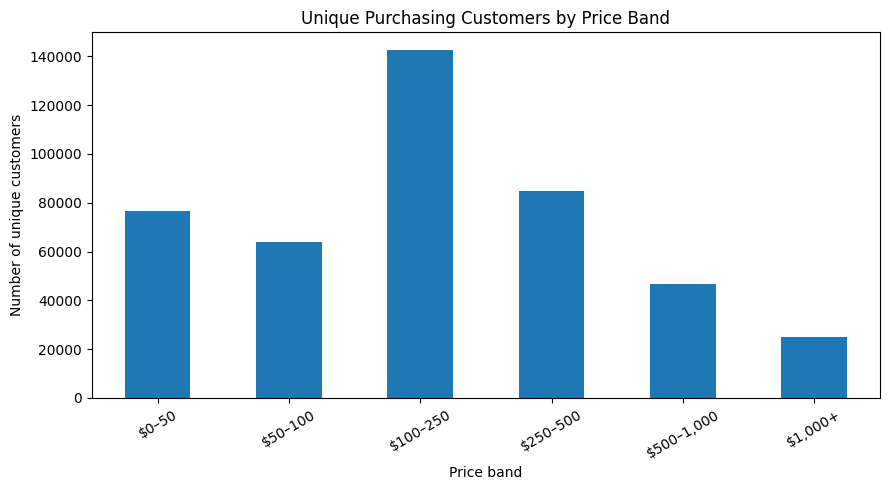

In [46]:
# Plot unique purchasing customers by price band
band_customer_summary.plot(
    x="price_band",
    y="unique_customers",
    kind="bar",
    figsize=(9, 5),
    legend=False,
    title="Unique Purchasing Customers by Price Band",
    xlabel="Price band",
    ylabel="Number of unique customers",
    rot=30
)

plt.tight_layout()
plt.show()

The visualisation showed that the 100–250 price band attracted the highest number of distinct purchasing customers, at approximately 143,000, while the 1,000+ band had the lowest count, at approximately 25,000. This supports the earlier finding that mid-priced products accounted for the largest share of purchase events. The results suggest that products in the $100–250 range may be a useful focus for further product-level analysis and marketing experiments. However, customer counts alone cannot determine product profitability or explain why customers chose particular price ranges.

## 6.4 Segment insights and business recommendations


In [47]:
# Summarise customer segments and their average activity
final_segment_summary = (
    customer_summary
    .groupby("segment")
    .agg(
        customers=("user_id", "count"),
        avg_views=("views", "mean"),
        avg_carts=("carts", "mean"),
        avg_purchases=("purchases", "mean"),
        avg_sessions=("unique_sessions", "mean")
    )
    .round(2)
)

# Calculate each segment's share of all customers
final_segment_summary["percentage"] = (
    final_segment_summary["customers"]
    / len(customer_summary) * 100
).round(2)

# Display the summary
final_segment_summary.sort_values(
    "customers", ascending=False
)

,customers,avg_views,avg_carts,avg_purchases,avg_sessions,percentage
segment,,,,,,
Browsers only,2540832,9.45,0.00,0.00,2.36,84.07
Purchasers,347118,36.72,1.97,2.14,7.13,11.49
Cart users (no purchase),134340,29.91,1.80,0.00,5.79,4.44


In [48]:
# Combine purchase-event and unique-customer summaries
price_band_business_summary = purchase_band_counts.merge(
    band_customer_summary,
    on="price_band"
)

price_band_business_summary = (
    price_band_business_summary
    .sort_values("purchase_events", ascending=False)
    .reset_index(drop=True)
)

price_band_business_summary

,price_band,purchase_events,percentage,unique_customers
0,$100–250,249314,33.56,142729
1,$250–500,147781,19.89,84983
2,$0–50,117072,15.76,76448
3,$50–100,92305,12.43,63872
4,"$500–1,000",86973,11.71,46513
5,"$1,000+",49404,6.65,25083


## 6.5 Business Insights and Recommendations

Browsers accounted for 84.07% of customers and recorded no cart or purchase events during October 2019. The business could investigate product-page usability, search relevance and personalised recommendations. A controlled experiment could measure whether these improvements increase cart activity.

A further 4.44% of customers recorded cart events without a purchase during the observation period. The business could review checkout usability, delivery charges and payment options, then test changes to determine whether they improve purchase completion.

Products priced between $100 and $250 accounted for 33.56% of purchase events and attracted 142,729 distinct purchasing customers. The business could examine individual products in this band and test product recommendations or promotions to determine whether they improve performance.

Customers with more recorded sessions had higher purchase incidence. The business could test relevant reminders or personalised product recommendations for returning customers, while evaluating the results rather than assuming more visits will cause purchases.

The analysis identified unusual patterns in some category-level cart counts. The business should validate event tracking and establish consistent session-level metrics before relying on these figures for operational decisions.

Overall, the analysis identifies opportunities to improve browsing engagement, investigate cart abandonment and better understand product-price performance. These recommendations should be tested and evaluated using clearly defined metrics, including session-level conversion rates and purchase outcomes.


# EDA Summary and Preliminary Findings

The exploratory data analysis examined approximately 42.45 million e-commerce events from 3.02 million unique customers during October 2019. The analysis investigated customer activity, product and category performance, time-based trends, session behaviour, and customer purchasing patterns.

The findings showed that most customers were classified as browsers, while a smaller proportion recorded cart activity without a purchase during the observation period. Electronics recorded the highest purchase volume among the main product categories, while products priced between $100 and $250 accounted for a substantial share of purchase events. Customer activity also varied by time, with browsing peaking in the afternoon and cart and purchase activity peaking in the morning.

These findings highlight potential opportunities to investigate customer engagement, product discovery, checkout barriers, and the performance of different price ranges. However, the results are based on event data from a single month, and customer activity or event overlap should not automatically be interpreted as a true conversion rate. The subsequent statistical analysis, SQL queries, and Tableau dashboard provide additional perspectives for evaluating these patterns and communicating the findings.


# 7 Statistical Analysis

## 7.1 Price differences across event types

In [25]:
file_path = "/content/drive/MyDrive/Ecommerce_Analytics/2019-Oct-full-cleaned.csv"

# Read only the columns needed for this analysis
df_check = pd.read_csv(
    file_path,
    usecols=["event_type", "price"],
    nrows=10
)

display(df_check)
print("\nColumn data types:")
print(df_check.dtypes)

,event_type,price
0,view,35.79
1,view,33.20
2,view,543.10
3,view,251.74
4,view,1081.98
5,view,908.62
6,view,380.96
7,view,41.16
8,view,102.71
9,view,566.01



Column data types:
event_type     object
price         float64
dtype: object


In [26]:
#Prepare the price distributions
price_data = {
    "view": [],
    "cart": [],
    "purchase": []
}

chunksize = 1_000_000

for chunk in pd.read_csv(
    file_path,
    usecols=["event_type", "price"],
    chunksize=chunksize
):
    # Keep only the three event types and valid positive prices
    chunk = chunk[
        chunk["event_type"].isin(["view", "cart", "purchase"])
        & (chunk["price"] > 0)
        & chunk["price"].notna()
    ]

    for event in price_data:
        prices = chunk.loc[
            chunk["event_type"] == event, "price"
        ].tolist()

        price_data[event].extend(prices)

print("Data preparation complete!")

for event, prices in price_data.items():
    print(f"{event.title()}: {len(prices):,} valid price observations")

Data preparation complete!
View: 40,710,876 valid price observations
Cart: 926,364 valid price observations
Purchase: 742,849 valid price observations


In [27]:
#Calculate descriptive statistics
price_summary = pd.DataFrame({
    event: pd.Series(prices).describe(
        percentiles=[0.25, 0.50, 0.75]
    )
    for event, prices in price_data.items()
}).T

price_summary = price_summary[
    ["count", "mean", "std", "min", "25%", "50%", "75%", "max"]
]

price_summary = price_summary.rename(columns={
    "count": "observations",
    "mean": "mean_price",
    "std": "std_price",
    "min": "min_price",
    "25%": "q1_price",
    "50%": "median_price",
    "75%": "q3_price",
    "max": "max_price"
})

display(price_summary.round(2))

,observations,mean_price,std_price,min_price,q1_price,median_price,q3_price,max_price
view,40710876.0,289.47,358.62,0.77,64.87,161.84,358.44,2574.07
cart,926364.0,333.88,351.85,1.00,130.48,197.04,394.30,2574.04
purchase,742849.0,309.56,348.87,0.77,87.49,179.84,375.21,2574.07


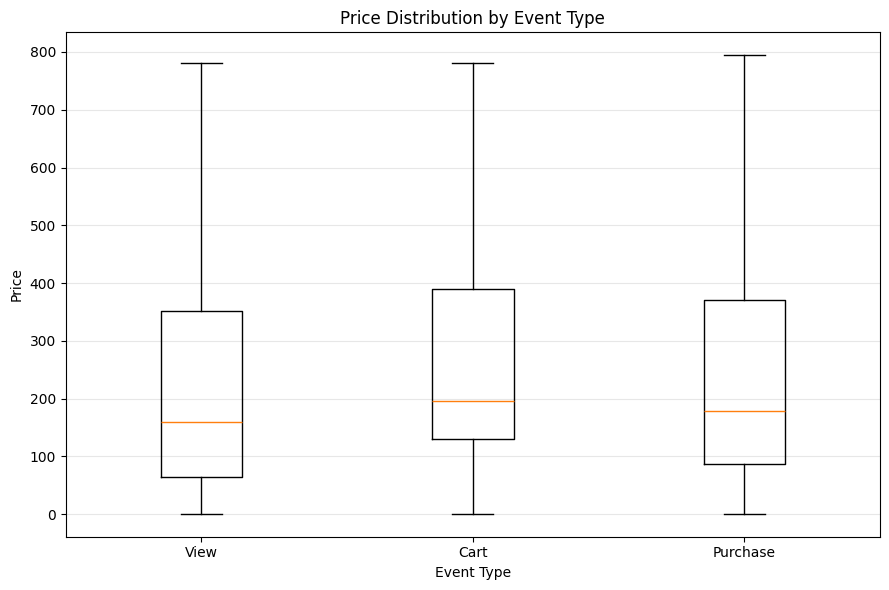

In [29]:
import matplotlib.pyplot as plt

# Create a reproducible sample for visualisation
plot_data = {}

for event, prices in price_data.items():
    sample_size = min(50_000, len(prices))

    plot_data[event.title()] = (
        pd.Series(prices)
        .sample(n=sample_size, random_state=42)
        .tolist()
    )

# Draw the box plot
plt.figure(figsize=(9, 6))

plt.boxplot(
    [plot_data["View"], plot_data["Cart"], plot_data["Purchase"]],
    tick_labels=["View", "Cart", "Purchase"],
    showfliers=False
)

plt.title("Price Distribution by Event Type")
plt.xlabel("Event Type")
plt.ylabel("Price")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Cart events have the highest median price (197.04), followed by purchases (179.84) and views (161.84).

Cart events also have the highest Q1 and Q3, suggesting that prices associated with cart events tend to be higher across the middle 50% of observations.

Purchase prices fall between view and cart prices for the mean, median and quartiles.

All three distributions have high maximum values relative to their medians, suggesting substantial right-skew. The box plot hides individual outliers, which is why the whiskers don't extend to the maximum values.

##7.2 Kruskal-Wallis Tes

In [30]:

from scipy.stats import kruskal

statistic, p_value = kruskal(
    price_data["view"],
    price_data["cart"],
    price_data["purchase"]
)

print(f"Kruskal-Wallis statistic: {statistic:.4f}")
print(f"P-value: {p_value:.6e}")

if p_value < 0.05:
    print("Result: There is evidence that at least one event type has a different price distribution.")
else:
    print("Result: There is insufficient evidence of a difference in price distributions.")

Kruskal-Wallis statistic: 64413.1372
P-value: 0.000000e+00
Result: There is evidence that at least one event type has a different price distribution.


Since the p-value is below 0.05, the null hypothesis about that the three groups have the same price distribution is rejected. There is strong statistical evidence that at least one event type has a different price distribution. This agrees with the descriptive statistics: cart events have the highest median price (197.04), followed by purchases (179.84) and views (161.84).

Comparing Product Prices Across Event Types

Objective

To investigate whether product prices differ across viewing, cart, and purchase events.

Methodology

I used the Kruskal–Wallis test to compare the price distributions of view, cart, and purchase events. This non-parametric test was selected because product prices were not normally distributed. Only records with valid, positive prices were included.

The Kruskal–Wallis test produced a statistic of 64,413.14 and a p-value below the displayed numerical precision. This provides strong evidence that the price distributions differ across at least some event types.

Cart events had the highest mean and median prices, followed by purchase events and view events. This suggests that higher-priced products may be more prominent among cart and purchase activity than among views.

Business Implications

Businesses could examine whether higher-priced products require different promotional strategies or additional purchase incentives. However, these results do not establish that price causes differences in customer behaviour.

Limitations

The dataset contains repeated events involving the same products and users, so observations may not be independent. The large sample size can also make small differences statistically significant. The findings should therefore be treated as exploratory.

## 7.3 Price and product activity

In [31]:
#Aggregate the data at product level
chunksize = 1_000_000

# Store aggregated activity by product
product_stats = {}

for chunk in pd.read_csv(
    file_path,
    usecols=["product_id", "event_type", "price"],
    chunksize=chunksize
):
    # Exclude rows without a product ID or a valid positive price
    chunk = chunk[
        chunk["product_id"].notna()
        & chunk["price"].notna()
        & (chunk["price"] > 0)
    ]

    # Aggregate within this chunk
    grouped = chunk.groupby(["product_id", "event_type"]).agg(
        event_count=("event_type", "size"),
        total_price=("price", "sum"),
        price_count=("price", "count")
    )

    # Merge chunk-level totals into the running product totals
    for (product_id, event_type), row in grouped.iterrows():
        if product_id not in product_stats:
            product_stats[product_id] = {
                "total_price": 0,
                "price_count": 0,
                "view_events": 0,
                "cart_events": 0,
                "purchase_events": 0
            }

        product_stats[product_id]["total_price"] += row["total_price"]
        product_stats[product_id]["price_count"] += row["price_count"]

        if event_type in ["view", "cart", "purchase"]:
            product_stats[product_id][f"{event_type}_events"] += row["event_count"]

print(f"Aggregation complete. Products found: {len(product_stats):,}")

Aggregation complete. Products found: 165,647


In [32]:
#Product level dt

# Convert the aggregated dictionary into a DataFrame
product_df = pd.DataFrame.from_dict(
    product_stats,
    orient="index"
)

# Calculate average observed price for each product
product_df["average_price"] = (
    product_df["total_price"] / product_df["price_count"]
)

# Reset the product ID index
product_df.index.name = "product_id"
product_df = product_df.reset_index()

# Show the columns we need for analysis
product_df = product_df[
    [
        "product_id",
        "average_price",
        "view_events",
        "cart_events",
        "purchase_events"
    ]
]

display(product_df.head())
print("\nNumber of products:", f"{len(product_df):,}")
print("\nMissing values:")
print(product_df.isnull().sum())

,product_id,average_price,view_events,cart_events,purchase_events
0,1001588,128.126156,2264.0,0.0,12.0
1,1002042,78.298841,320.0,5.0,3.0
2,1002062,104.127135,1556.0,0.0,18.0
3,1002098,371.702313,3636.0,0.0,13.0
4,1002099,373.747491,18275.0,0.0,153.0



Number of products: 165,647

Missing values:
product_id         0
average_price      0
view_events        0
cart_events        0
purchase_events    0
dtype: int64


In [33]:
#Calculate Spearman correlations

from scipy.stats import spearmanr

activity_columns = [
    "view_events",
    "cart_events",
    "purchase_events"
]

correlation_results = []

for column in activity_columns:
    correlation, p_value = spearmanr(
        product_df["average_price"],
        product_df[column]
    )

    correlation_results.append({
        "activity": column,
        "spearman_correlation": correlation,
        "p_value": p_value
    })

correlation_df = pd.DataFrame(correlation_results)

display(correlation_df.round(6))

,activity,spearman_correlation,p_value
0,view_events,0.222376,0.0
1,cart_events,0.070718,0.0
2,purchase_events,0.074340,0.0


Views (ρ=0.2224): A weak positive association. Higher-priced products tend to have somewhat higher view counts, although the relationship is not strong.

Cart events (ρ=0.0707): A very weak positive association. Product price has little monotonic association with the number of cart events.

Purchase events (ρ=0.0743): A very weak positive association. Higher-priced products tend to have slightly higher purchase counts, but the relationship is weak.

All three coefficients are positive, but the relationships are much weaker for cart and purchase activity than for views.

The results suggest that higher-priced products may attract more views, but price alone has little association with how often products are added to carts or purchased.

This could mean that other factors, such as brand, product category, product popularity and customer demand, are also important. However, our analysis does not test those explanations directly.

Because 165,647 products were analysed, very small associations can still produce extremely small p-values. Statistical significance does not mean the relationship is strong or commercially important.

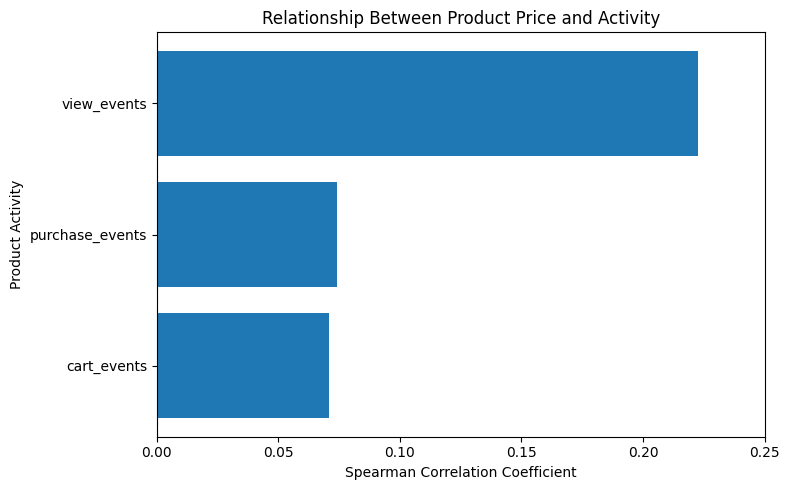

In [34]:
# Sort the results from strongest to weakest correlation
plot_df = correlation_df.sort_values(
    "spearman_correlation",
    ascending=True
)

# Create the bar chart
plt.figure(figsize=(8, 5))

plt.barh(
    plot_df["activity"],
    plot_df["spearman_correlation"]
)

# Add a reference line at zero
plt.axvline(x=0, linestyle="--")

plt.title("Relationship Between Product Price and Activity")
plt.xlabel("Spearman Correlation Coefficient")
plt.ylabel("Product Activity")
plt.xlim(0, 0.25)

plt.tight_layout()
plt.show()

Relationship Between Product Price and Activity

Objective

To examine whether product price is associated with the number of views, cart events, and purchase events received by a product.

Methodology

I aggregated the dataset at product level, calculating each product's average observed price and its total number of view, cart, and purchase events. I then used Spearman's rank correlation to assess the direction and strength of the relationships without assuming a linear relationship or normally distributed variables.

All three correlations were positive. Price had the strongest association with view counts, while its associations with cart and purchase counts were considerably weaker. The p-values were displayed as zero due to numerical precision; they should be interpreted as extremely small rather than literally zero.

Business Implications

Product price alone appears to have limited association with cart and purchase activity. Businesses may benefit from investigating other factors, such as product category, brand, and customer demand, when evaluating product performance.

Limitations

Correlation does not imply causation. Product popularity, category differences, availability, and other factors may influence activity counts. The analysis also uses data from October 2019 only, so the findings may not represent current customer behaviour.

# 8 SQL Analysis Using SQLite

## 8.1 Preparing the dataset for SQL Analysis

The SQL analysis was performed using a sample containing the first one million rows of the October 2019 dataset, rather than the full dataset of approximately 42.45 million rows. As the sample covers only part of the month, the results are exploratory and may not represent customer behaviour throughout October 2019. Findings from this section should therefore be interpreted with this limitation in mind.

In [1]:
import os

from google.colab import drive
drive.mount('/content/drive')

file_path = "/content/drive/MyDrive/Ecommerce_Analytics/2019-Oct-full-cleaned.csv"

if os.path.exists(file_path):
    print("Dataset found!")
    print(f"File size: {os.path.getsize(file_path) / (1024**3):.2f} GB")
else:
    print("Dataset not found. Please check the file path.")

Mounted at /content/drive
Dataset found!
File size: 7.45 GB


In [2]:
import pandas as pd

# Original cleaned dataset
file_path = "/content/drive/MyDrive/Ecommerce_Analytics/2019-Oct-full-cleaned.csv"

# Output dataset for SQL
sql_csv_path = "/content/drive/MyDrive/Ecommerce_Analytics/ecommerce_sql.csv"

# Columns needed for our SQL analysis
sql_columns = [
    "event_time",
    "event_type",
    "product_id",
    "category_code",
    "main_category",
    "brand_clean",
    "price",
    "user_id",
    "user_session"
]

print("Checking the columns in the cleaned dataset...")

sample = pd.read_csv(file_path, nrows=5)

print(sample.columns.tolist())

Checking the columns in the cleaned dataset...
['event_time', 'event_type', 'product_id', 'category_id', 'category_code', 'brand', 'price', 'user_id', 'user_session', 'date', 'hour', 'day_of_week', 'is_weekend', 'main_category', 'brand_clean', 'price_band']


The selected columns were chosen based on the business questions this project aims to answer. Event timestamps and event types allow us to analyse customer activity over time and distinguish between views, cart additions and purchases. Product IDs, category information and brand names support product and category performance analysis, while price allows us to compare purchasing activity across different price ranges. User IDs and session IDs enable us to examine customer behaviour, identify unique users and sessions, and investigate the customer journey. By retaining only the relevant columns, we can reduce the dataset size and make it more manageable to import into SQLite and analyse using SQL.


In [3]:
file_path = "/content/drive/MyDrive/Ecommerce_Analytics/2019-Oct-full-cleaned.csv"
sql_csv_path = "/content/drive/MyDrive/Ecommerce_Analytics/ecommerce_sql_sample.csv"

sql_columns = [
    "event_time",
    "event_type",
    "product_id",
    "category_code",
    "main_category",
    "brand_clean",
    "price",
    "user_id",
    "user_session"
]

sample_size = 1_000_000
chunk_size = 500_000
sample_parts = []
rows_seen = 0

for chunk in pd.read_csv(
    file_path,
    usecols=sql_columns,
    chunksize=chunk_size
):
    remaining = sample_size - rows_seen

    if remaining <= 0:
        break

    selected = chunk.head(remaining)
    sample_parts.append(selected)
    rows_seen += len(selected)

    if rows_seen >= sample_size:
        break

sql_sample = pd.concat(sample_parts, ignore_index=True)
sql_sample.to_csv(sql_csv_path, index=False)

print(f"Rows saved: {len(sql_sample):,}")
print(f"Saved to: {sql_csv_path}")
print(f"File size: {__import__('os').path.getsize(sql_csv_path) / (1024**2):.2f} MB")

Rows saved: 1,000,000
Saved to: /content/drive/MyDrive/Ecommerce_Analytics/ecommerce_sql_sample.csv
File size: 118.58 MB


### 8.1.1 Create the SQLite database

In [4]:
import sqlite3

# Path where our SQLite database will be stored
db_path = "/content/drive/MyDrive/Ecommerce_Analytics/ecommerce.db"

# Connect to the database (creates it if it doesn't exist)
conn = sqlite3.connect(db_path)

print("SQLite database created and connected!")

SQLite database created and connected!


### 8.1.2 Import the CSV in SQLite

In [5]:
sql_csv_path = "/content/drive/MyDrive/Ecommerce_Analytics/ecommerce_sql_sample.csv"
db_path = "/content/drive/MyDrive/Ecommerce_Analytics/ecommerce.db"

conn = sqlite3.connect(db_path)

chunk_size = 100_000
first_chunk = True

for chunk in pd.read_csv(sql_csv_path, chunksize=chunk_size):

    chunk.to_sql(
        "events",
        conn,
        if_exists="replace" if first_chunk else "append",
        index=False
    )

    first_chunk = False

print("Data imported successfully!")

Data imported successfully!


In [6]:
# Check how many rows were imported
row_count = pd.read_sql_query(
    "SELECT COUNT(*) AS total_rows FROM events",
    conn
)

print(row_count)

# Preview the first five rows
preview = pd.read_sql_query(
    "SELECT * FROM events LIMIT 5",
    conn
)

display(preview)

   total_rows
0     1000000


,event_time,event_type,product_id,category_code,price,user_id,user_session,main_category,brand_clean
0,2019-10-01 00:00:00+00:00,view,44600062,None,35.79,541312140,72d76fde-8bb3-4e00-8c23-a032dfed738c,None,shiseido
1,2019-10-01 00:00:00+00:00,view,3900821,appliances.environment.water_heater,33.20,554748717,9333dfbd-b87a-4708-9857-6336556b0fcc,appliances,aqua
2,2019-10-01 00:00:01+00:00,view,17200506,furniture.living_room.sofa,543.10,519107250,566511c2-e2e3-422b-b695-cf8e6e792ca8,furniture,Unknown
3,2019-10-01 00:00:01+00:00,view,1307067,computers.notebook,251.74,550050854,7c90fc70-0e80-4590-96f3-13c02c18c713,computers,lenovo
4,2019-10-01 00:00:04+00:00,view,1004237,electronics.smartphone,1081.98,535871217,c6bd7419-2748-4c56-95b4-8cec9ff8b80d,electronics,apple


## 8.2 SQL for products with many views but relatively few cart events

In [14]:
query = """
WITH product_activity AS (
    SELECT
        product_id,
        main_category,
        brand_clean,
        SUM(CASE WHEN event_type = 'view' THEN 1 ELSE 0 END)
            AS view_events,
        SUM(CASE WHEN event_type = 'cart' THEN 1 ELSE 0 END)
            AS cart_events,
        SUM(CASE WHEN event_type = 'purchase' THEN 1 ELSE 0 END)
            AS purchase_events
    FROM events
    WHERE product_id IS NOT NULL
    GROUP BY product_id, main_category, brand_clean
)
SELECT
    product_id,
    main_category,
    brand_clean,
    view_events,
    cart_events,
    purchase_events,
    ROUND(
        1.0 * cart_events / view_events * 100,
        2
    ) AS cart_to_view_event_ratio_pct
FROM product_activity
WHERE view_events >= 50
ORDER BY cart_to_view_event_ratio_pct ASC,
         view_events DESC
LIMIT 10;
"""

product_engagement = pd.read_sql_query(query, conn)
display(product_engagement)

,product_id,main_category,brand_clean,view_events,cart_events,purchase_events,cart_to_view_event_ratio_pct
0,1005156,electronics,xiaomi,1632,0,14,0.0
1,1004433,electronics,samsung,1384,0,22,0.0
2,1003549,electronics,samsung,1005,0,6,0.0
3,1005157,electronics,xiaomi,971,0,8,0.0
4,1003769,electronics,huawei,899,0,7,0.0
5,28600026,None,Unknown,826,0,2,0.0
6,1005158,electronics,xiaomi,815,0,7,0.0
7,22700084,None,force,813,0,13,0.0
8,1005161,electronics,xiaomi,797,0,8,0.0
9,15100337,None,Unknown,780,0,9,0.0


Electronics dominates the list, particularly Xiaomi, Samsung and Huawei products.

Product 1005156 (Xiaomi) has the most views at 1,632, but no cart events in this sample.

These products could be candidates for further investigation into product information, pricing, availability or how customers interact with their product pages.

## 8.3 Brand-level engagement comparison

In [15]:
query = """
SELECT
    brand_clean,
    COUNT(DISTINCT product_id) AS unique_products,
    SUM(CASE WHEN event_type = 'view' THEN 1 ELSE 0 END)
        AS view_events,
    SUM(CASE WHEN event_type = 'cart' THEN 1 ELSE 0 END)
        AS cart_events,
    SUM(CASE WHEN event_type = 'purchase' THEN 1 ELSE 0 END)
        AS purchase_events,
    ROUND(
        1.0 * SUM(CASE WHEN event_type = 'cart' THEN 1 ELSE 0 END)
        / NULLIF(
            SUM(CASE WHEN event_type = 'view' THEN 1 ELSE 0 END),
            0
        ) * 100,
        2
    ) AS cart_to_view_event_ratio_pct
FROM events
GROUP BY brand_clean
HAVING SUM(CASE WHEN event_type = 'view' THEN 1 ELSE 0 END) >= 1000
ORDER BY cart_to_view_event_ratio_pct DESC
LIMIT 10;
"""

brand_engagement = pd.read_sql_query(query, conn)
display(brand_engagement)

,brand_clean,unique_products,view_events,cart_events,purchase_events,cart_to_view_event_ratio_pct
0,samsung,800,111479,5273,3963,4.73
1,apple,442,95451,4136,3480,4.33
2,oppo,27,8035,281,180,3.50
3,xiaomi,545,65759,2189,1298,3.33
4,huawei,105,26559,852,602,3.21
5,huter,79,1917,59,32,3.08
6,ariston,115,1818,49,66,2.70
7,starline,61,3087,77,32,2.49
8,kingston,180,1433,28,39,1.95
9,panasonic,198,2070,40,27,1.93


Samsung and Apple lead this sample in both view volume and cart-to-view event ratio.

Xiaomi has substantial browsing activity, but its cart-to-view ratio is lower than Samsung's and Apple's.

Product counts vary significantly between brands, so raw totals alone are not sufficient to compare brand performance fairly.

## 8.4 Purchase Events by Price Band

In [23]:
query = """
SELECT
    CASE
        WHEN price <= 0 THEN 'Unknown / $0'
        WHEN price <= 50 THEN '$0-$50'
        WHEN price <= 100 THEN '$50-$100'
        WHEN price <= 250 THEN '$100-$250'
        WHEN price <= 500 THEN '$250-$500'
        WHEN price <= 1000 THEN '$500-$1000'
        ELSE '$1000+'
    END AS price_band,
    COUNT(*) AS purchase_events
FROM events
WHERE event_type = 'purchase'
GROUP BY price_band
ORDER BY
    CASE price_band
        WHEN 'Unknown / $0' THEN 0
        WHEN '$0-$50' THEN 1
        WHEN '$50-$100' THEN 2
        WHEN '$100-$250' THEN 3
        WHEN '$250-$500' THEN 4
        WHEN '$500-$1000' THEN 5
        WHEN '$1000+' THEN 6
    END;
"""

price_band_results = pd.read_sql_query(query, conn)
display(price_band_results)

,price_band,purchase_events
0,$0-$50,2586
1,$50-$100,1907
2,$100-$250,5415
3,$250-$500,3597
4,$500-$1000,2317
5,$1000+,1026


Products priced between $100 and $500 account for a large share of the recorded purchase activity in this sample. This could help guide further pricing and merchandising analysis, although purchase counts alone don't prove that these products have better conversion rates or generate more revenue.

## 8.5 Products analysis for most cart attracted but have relatively few purchases

In [12]:
query = """
WITH product_activity AS (
    SELECT
        product_id,
        main_category,
        brand_clean,
        SUM(CASE WHEN event_type = 'view' THEN 1 ELSE 0 END)
            AS view_events,
        SUM(CASE WHEN event_type = 'cart' THEN 1 ELSE 0 END)
            AS cart_events,
        SUM(CASE WHEN event_type = 'purchase' THEN 1 ELSE 0 END)
            AS purchase_events
    FROM events
    WHERE product_id IS NOT NULL
    GROUP BY product_id, main_category, brand_clean
)
SELECT
    product_id,
    main_category,
    brand_clean,
    view_events,
    cart_events,
    purchase_events,
    ROUND(
        1.0 * purchase_events / cart_events * 100,
        2
    ) AS purchase_to_cart_event_ratio_pct
FROM product_activity
WHERE cart_events >= 20
ORDER BY purchase_to_cart_event_ratio_pct ASC,
         cart_events DESC
LIMIT 10;
"""

product_cart_analysis = pd.read_sql_query(query, conn)
display(product_cart_analysis)

,product_id,main_category,brand_clean,view_events,cart_events,purchase_events,purchase_to_cart_event_ratio_pct
0,1005004,electronics,huawei,385,61,14,22.95
1,1005072,electronics,samsung,438,26,6,23.08
2,11400268,None,xiaomi,375,39,10,25.64
3,1004792,electronics,xiaomi,869,26,7,26.92
4,5100503,None,xiaomi,796,36,11,30.56
5,6000094,auto,starline,726,42,13,30.95
6,5100854,electronics,apple,151,22,7,31.82
7,19200005,construction,huter,229,22,7,31.82
8,1005008,electronics,xiaomi,1446,107,36,33.64
9,1004886,electronics,oppo,621,35,12,34.29


Product 1005004 is a potential candidate for further investigation because it recorded 61 cart events but only 14 purchase events in the sample. The business could investigate its price, product description, availability, and checkout experience to see whether any issues might explain the observed pattern.

However, we cannot conclude that 47 cart events represent 47 abandoned purchases. Events may come from different users or sessions, and the purchase could have happened outside the observed sample.

In [24]:
from pathlib import Path

sql_content = r"""
-- E-commerce Product Analytics & Conversion Analysis
-- Database table: events
-- Dataset: First 1 million rows of October 2019 data
-- Note: Event ratios are not true customer conversion rates.


-- QUERY 1: Product Views-to-Cart Event Ratio

WITH product_activity AS (
    SELECT
        product_id,
        main_category,
        brand_clean,
        SUM(CASE WHEN event_type = 'view' THEN 1 ELSE 0 END)
            AS view_events,
        SUM(CASE WHEN event_type = 'cart' THEN 1 ELSE 0 END)
            AS cart_events,
        SUM(CASE WHEN event_type = 'purchase' THEN 1 ELSE 0 END)
            AS purchase_events
    FROM events
    WHERE product_id IS NOT NULL
    GROUP BY product_id, main_category, brand_clean
)
SELECT
    product_id,
    main_category,
    brand_clean,
    view_events,
    cart_events,
    purchase_events,
    ROUND(
        1.0 * cart_events / view_events * 100,
        2
    ) AS cart_to_view_event_ratio_pct
FROM product_activity
WHERE view_events >= 50
ORDER BY cart_to_view_event_ratio_pct ASC,
         view_events DESC
LIMIT 10;


-- QUERY 2: Brand-Level Engagement Comparison

SELECT
    brand_clean,
    COUNT(DISTINCT product_id) AS unique_products,
    SUM(CASE WHEN event_type = 'view' THEN 1 ELSE 0 END)
        AS view_events,
    SUM(CASE WHEN event_type = 'cart' THEN 1 ELSE 0 END)
        AS cart_events,
    SUM(CASE WHEN event_type = 'purchase' THEN 1 ELSE 0 END)
        AS purchase_events,
    ROUND(
        1.0 * SUM(CASE WHEN event_type = 'cart' THEN 1 ELSE 0 END)
        / NULLIF(
            SUM(CASE WHEN event_type = 'view' THEN 1 ELSE 0 END),
            0
        ) * 100,
        2
    ) AS cart_to_view_event_ratio_pct
FROM events
GROUP BY brand_clean
HAVING SUM(CASE WHEN event_type = 'view' THEN 1 ELSE 0 END) >= 1000
ORDER BY cart_to_view_event_ratio_pct DESC
LIMIT 10;


-- QUERY 3: Purchase Events by Price Band

SELECT
    CASE
        WHEN price <= 0 THEN 'Unknown / $0'
        WHEN price <= 50 THEN '$0-$50'
        WHEN price <= 100 THEN '$50-$100'
        WHEN price <= 250 THEN '$100-$250'
        WHEN price <= 500 THEN '$250-$500'
        WHEN price <= 1000 THEN '$500-$1000'
        ELSE '$1000+'
    END AS price_band,
    COUNT(*) AS purchase_events
FROM events
WHERE event_type = 'purchase'
GROUP BY price_band
ORDER BY
    CASE price_band
        WHEN 'Unknown / $0' THEN 0
        WHEN '$0-$50' THEN 1
        WHEN '$50-$100' THEN 2
        WHEN '$100-$250' THEN 3
        WHEN '$250-$500' THEN 4
        WHEN '$500-$1000' THEN 5
        WHEN '$1000+' THEN 6
    END;


-- QUERY 4: Product Cart-to-Purchase Event Ratio

WITH product_activity AS (
    SELECT
        product_id,
        main_category,
        brand_clean,
        SUM(CASE WHEN event_type = 'view' THEN 1 ELSE 0 END)
            AS view_events,
        SUM(CASE WHEN event_type = 'cart' THEN 1 ELSE 0 END)
            AS cart_events,
        SUM(CASE WHEN event_type = 'purchase' THEN 1 ELSE 0 END)
            AS purchase_events
    FROM events
    WHERE product_id IS NOT NULL
    GROUP BY product_id, main_category, brand_clean
)
SELECT
    product_id,
    main_category,
    brand_clean,
    view_events,
    cart_events,
    purchase_events,
    ROUND(
        1.0 * purchase_events / cart_events * 100,
        2
    ) AS purchase_to_cart_event_ratio_pct
FROM product_activity
WHERE cart_events >= 20
ORDER BY purchase_to_cart_event_ratio_pct ASC,
         cart_events DESC
LIMIT 10;
"""

sql_path = Path(
    "/content/drive/MyDrive/Ecommerce_Analytics/ecommerce_analysis.sql"
)

sql_path.write_text(sql_content, encoding="utf-8")

print("SQL file saved:", sql_path)
print("File exists:", sql_path.exists())
print("File size:", sql_path.stat().st_size, "bytes")

SQL file saved: /content/drive/MyDrive/Ecommerce_Analytics/ecommerce_analysis.sql
File exists: True
File size: 3443 bytes


# 9 Tableau

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os

folder_path = "/content/drive/MyDrive/Ecommerce_Analytics"

print("Folder exists:", os.path.exists(folder_path))

if os.path.exists(folder_path):
    print("\nFiles in Ecommerce_Analytics:")
    for filename in os.listdir(folder_path):
        print("-", filename)

Folder exists: True

Files in Ecommerce_Analytics:
- 2019-Oct-sample.csv
- 2019-Oct-sample-cleaned.csv
- 2019-Oct-full-cleaned.csv
- ecommerce_sql_sample.csv
- ecommerce.db
- ecommerce_analysis.sql


In [4]:

import pandas as pd
import os

file_path = "/content/drive/MyDrive/Ecommerce_Analytics/2019-Oct-full-cleaned.csv"

df_preview = pd.read_csv(file_path, nrows=5)

print("Columns:")
print(df_preview.columns.tolist())

print("\nData types:")
print(df_preview.dtypes)

print("\nPreview:")
display(df_preview)

Columns:
['event_time', 'event_type', 'product_id', 'category_id', 'category_code', 'brand', 'price', 'user_id', 'user_session', 'date', 'hour', 'day_of_week', 'is_weekend', 'main_category', 'brand_clean', 'price_band']

Data types:
event_time        object
event_type        object
product_id         int64
category_id        int64
category_code     object
brand             object
price            float64
user_id            int64
user_session      object
date              object
hour               int64
day_of_week       object
is_weekend          bool
main_category     object
brand_clean       object
price_band        object
dtype: object

Preview:


,event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session,date,hour,day_of_week,is_weekend,main_category,brand_clean,price_band
0,2019-10-01 00:00:00+00:00,view,44600062,2103807459595387724,NaN,shiseido,35.79,541312140,72d76fde-8bb3-4e00-8c23-a032dfed738c,2019-10-01,0,Tuesday,False,NaN,shiseido,$0–50
1,2019-10-01 00:00:00+00:00,view,3900821,2053013552326770905,appliances.environment.water_heater,aqua,33.20,554748717,9333dfbd-b87a-4708-9857-6336556b0fcc,2019-10-01,0,Tuesday,False,appliances,aqua,$0–50
2,2019-10-01 00:00:01+00:00,view,17200506,2053013559792632471,furniture.living_room.sofa,NaN,543.10,519107250,566511c2-e2e3-422b-b695-cf8e6e792ca8,2019-10-01,0,Tuesday,False,furniture,Unknown,"$500–1,000"
3,2019-10-01 00:00:01+00:00,view,1307067,2053013558920217191,computers.notebook,lenovo,251.74,550050854,7c90fc70-0e80-4590-96f3-13c02c18c713,2019-10-01,0,Tuesday,False,computers,lenovo,$250–500
4,2019-10-01 00:00:04+00:00,view,1004237,2053013555631882655,electronics.smartphone,apple,1081.98,535871217,c6bd7419-2748-4c56-95b4-8cec9ff8b80d,2019-10-01,0,Tuesday,False,electronics,apple,"$1,000+"


## 9.1 Summary file for daily activity

In [5]:
import pandas as pd

file_path = "/content/drive/MyDrive/Ecommerce_Analytics/2019-Oct-full-cleaned.csv"
output_folder = "/content/drive/MyDrive/Ecommerce_Analytics"

daily_results = []

for chunk in pd.read_csv(
    file_path,
    usecols=["date", "hour", "event_type"],
    chunksize=1_000_000
):
    # Count events by date, hour, and event type
    counts = (
        chunk.groupby(["date", "hour", "event_type"])
        .size()
        .unstack(fill_value=0)
    )

    daily_results.append(counts)

# Combine the counts from all chunks
daily_summary = pd.concat(daily_results).groupby(
    level=[0, 1]
).sum()

# Make sure all event types have a column
for event in ["view", "cart", "purchase"]:
    if event not in daily_summary.columns:
        daily_summary[event] = 0

daily_summary = daily_summary[["view", "cart", "purchase"]]
daily_summary = daily_summary.reset_index()

daily_summary = daily_summary.rename(columns={
    "view": "view_events",
    "cart": "cart_events",
    "purchase": "purchase_events"
})

output_path = os.path.join(
    output_folder, "tableau_daily_activity.csv"
)

daily_summary.to_csv(output_path, index=False)

print("Daily activity summary saved!")
print("Rows:", len(daily_summary))
print("File size (MB):", round(os.path.getsize(output_path) / (1024 ** 2), 2))

display(daily_summary.head())

Daily activity summary saved!
Rows: 744
File size (MB): 0.02


event_type,date,hour,view_events,cart_events,purchase_events
0,2019-10-01,0,1070,3,10
1,2019-10-01,1,121,0,0
2,2019-10-01,2,22326,244,316
3,2019-10-01,3,47951,613,845
4,2019-10-01,4,53390,879,1021


## 9.2 Create the product and brand performance summary file

In [6]:
file_path = "/content/drive/MyDrive/Ecommerce_Analytics/2019-Oct-full-cleaned.csv"
output_folder = "/content/drive/MyDrive/Ecommerce_Analytics"

summary_results = []

for chunk in pd.read_csv(
    file_path,
    usecols=[
        "main_category",
        "brand_clean",
        "price_band",
        "event_type"
    ],
    chunksize=1_000_000
):
    # Replace missing category values with a readable label
    chunk["main_category"] = chunk["main_category"].fillna("Unknown")

    # Count events by category, brand, price band, and event type
    counts = (
        chunk.groupby(
            ["main_category", "brand_clean", "price_band", "event_type"],
            dropna=False
        )
        .size()
        .unstack(fill_value=0)
    )

    summary_results.append(counts)

# Combine counts from all chunks
product_summary = pd.concat(summary_results).groupby(
    level=[0, 1, 2]
).sum()

# Ensure all event types have a column
for event in ["view", "cart", "purchase"]:
    if event not in product_summary.columns:
        product_summary[event] = 0

product_summary = product_summary[["view", "cart", "purchase"]]
product_summary = product_summary.reset_index()

product_summary = product_summary.rename(columns={
    "main_category": "category",
    "brand_clean": "brand",
    "view": "view_events",
    "cart": "cart_events",
    "purchase": "purchase_events"
})

output_path = os.path.join(
    output_folder, "tableau_product_performance.csv"
)

product_summary.to_csv(output_path, index=False)

print("Product performance summary saved!")
print("Rows:", len(product_summary))
print("File size (MB):", round(os.path.getsize(output_path) / (1024 ** 2), 2))

display(product_summary.head())

Product performance summary saved!
Rows: 9082
File size (MB): 0.3


event_type,category,brand,price_band,view_events,cart_events,purchase_events
0,Unknown,Unknown,$0–50,1058448,3280,14201
1,Unknown,Unknown,"$1,000+",96972,18,242
2,Unknown,Unknown,$100–250,1056295,1710,10868
3,Unknown,Unknown,$250–500,669072,289,5959
4,Unknown,Unknown,"$500–1,000",190663,116,811


## 9.3 Create files for the customer acitivity summary

In [7]:
file_path = "/content/drive/MyDrive/Ecommerce_Analytics/2019-Oct-full-cleaned.csv"
output_folder = "/content/drive/MyDrive/Ecommerce_Analytics"

customer_results = []

for chunk in pd.read_csv(
    file_path,
    usecols=["user_id", "event_type"],
    chunksize=1_000_000
):
    # Exclude records without a customer ID
    chunk = chunk.dropna(subset=["user_id"])

    # Count events by customer and event type
    counts = (
        chunk.groupby(["user_id", "event_type"])
        .size()
        .unstack(fill_value=0)
    )

    customer_results.append(counts)

# Combine counts across all chunks
customer_summary = pd.concat(customer_results).groupby(
    level=0
).sum()

# Ensure every event type exists
for event in ["view", "cart", "purchase"]:
    if event not in customer_summary.columns:
        customer_summary[event] = 0

customer_summary = customer_summary[["view", "cart", "purchase"]]

# Classify each customer
customer_summary["customer_segment"] = "Browsers only"

customer_summary.loc[
    customer_summary["cart"] > 0,
    "customer_segment"
] = "Cart, no purchase"

customer_summary.loc[
    customer_summary["purchase"] > 0,
    "customer_segment"
] = "Purchasers"

# Summarise the number of customers in each segment
segment_summary = (
    customer_summary.groupby("customer_segment")
    .agg(
        customers=("view", "size"),
        total_views=("view", "sum"),
        total_cart_events=("cart", "sum"),
        total_purchase_events=("purchase", "sum")
    )
    .reset_index()
)

# Calculate the share of customers
segment_summary["customer_share_pct"] = (
    segment_summary["customers"]
    / segment_summary["customers"].sum()
    * 100
)

output_path = os.path.join(
    output_folder, "tableau_customer_activity.csv"
)

segment_summary.to_csv(output_path, index=False)

print("Customer activity summary saved!")
print("Rows:", len(segment_summary))
print("File size (KB):", round(os.path.getsize(output_path) / 1024, 2))

display(segment_summary)

Customer activity summary saved!
Rows: 3
File size (KB): 0.27


,customer_segment,customers,total_views,total_cart_events,total_purchase_events,customer_share_pct
0,Browsers only,2540832,24015563,0,0,84.069762
1,"Cart, no purchase",134340,4018358,241596,0,4.444974
2,Purchasers,347118,12745478,684918,742849,11.485264


Verify the files

In [8]:
folder_path = "/content/drive/MyDrive/Ecommerce_Analytics"

tableau_files = [
    "tableau_daily_activity.csv",
    "tableau_product_performance.csv",
    "tableau_customer_activity.csv"
]

for filename in tableau_files:
    file_path = os.path.join(folder_path, filename)

    print(f"\n{filename}")
    print("Exists:", os.path.exists(file_path))

    if os.path.exists(file_path):
        print(
            "Size (KB):",
            round(os.path.getsize(file_path) / 1024, 2)
        )

        preview = pd.read_csv(file_path, nrows=3)
        print("Columns:", preview.columns.tolist())


tableau_daily_activity.csv
Exists: True
Size (KB): 20.75
Columns: ['date', 'hour', 'view_events', 'cart_events', 'purchase_events']

tableau_product_performance.csv
Exists: True
Size (KB): 310.07
Columns: ['category', 'brand', 'price_band', 'view_events', 'cart_events', 'purchase_events']

tableau_customer_activity.csv
Exists: True
Size (KB): 0.27
Columns: ['customer_segment', 'customers', 'total_views', 'total_cart_events', 'total_purchase_events', 'customer_share_pct']


## 9.4 Tableau Dashboard and Analysis

**Figure 1. Tableau Dashboard — Product Performance**

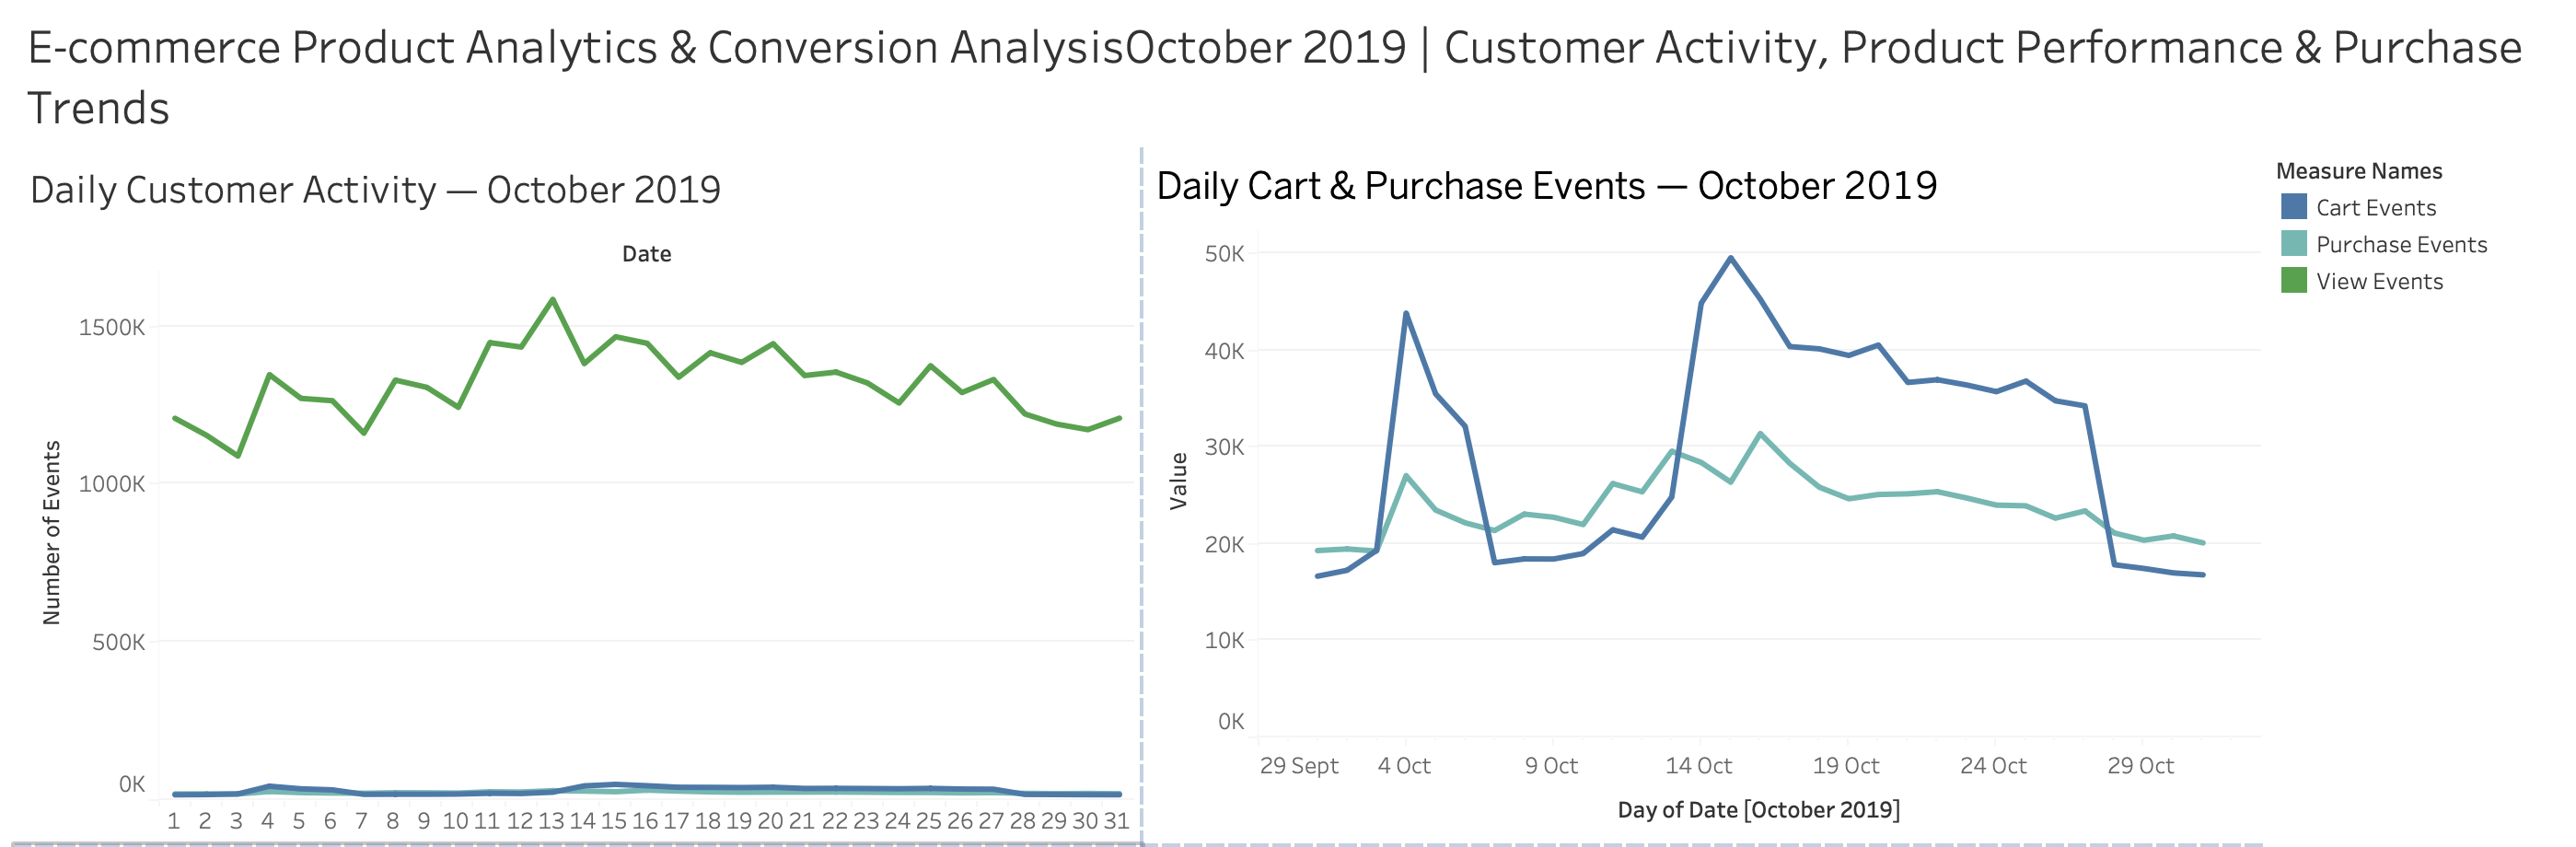

**Figure 2. Tableau Dashboard — Price Bands and Customer Segments**

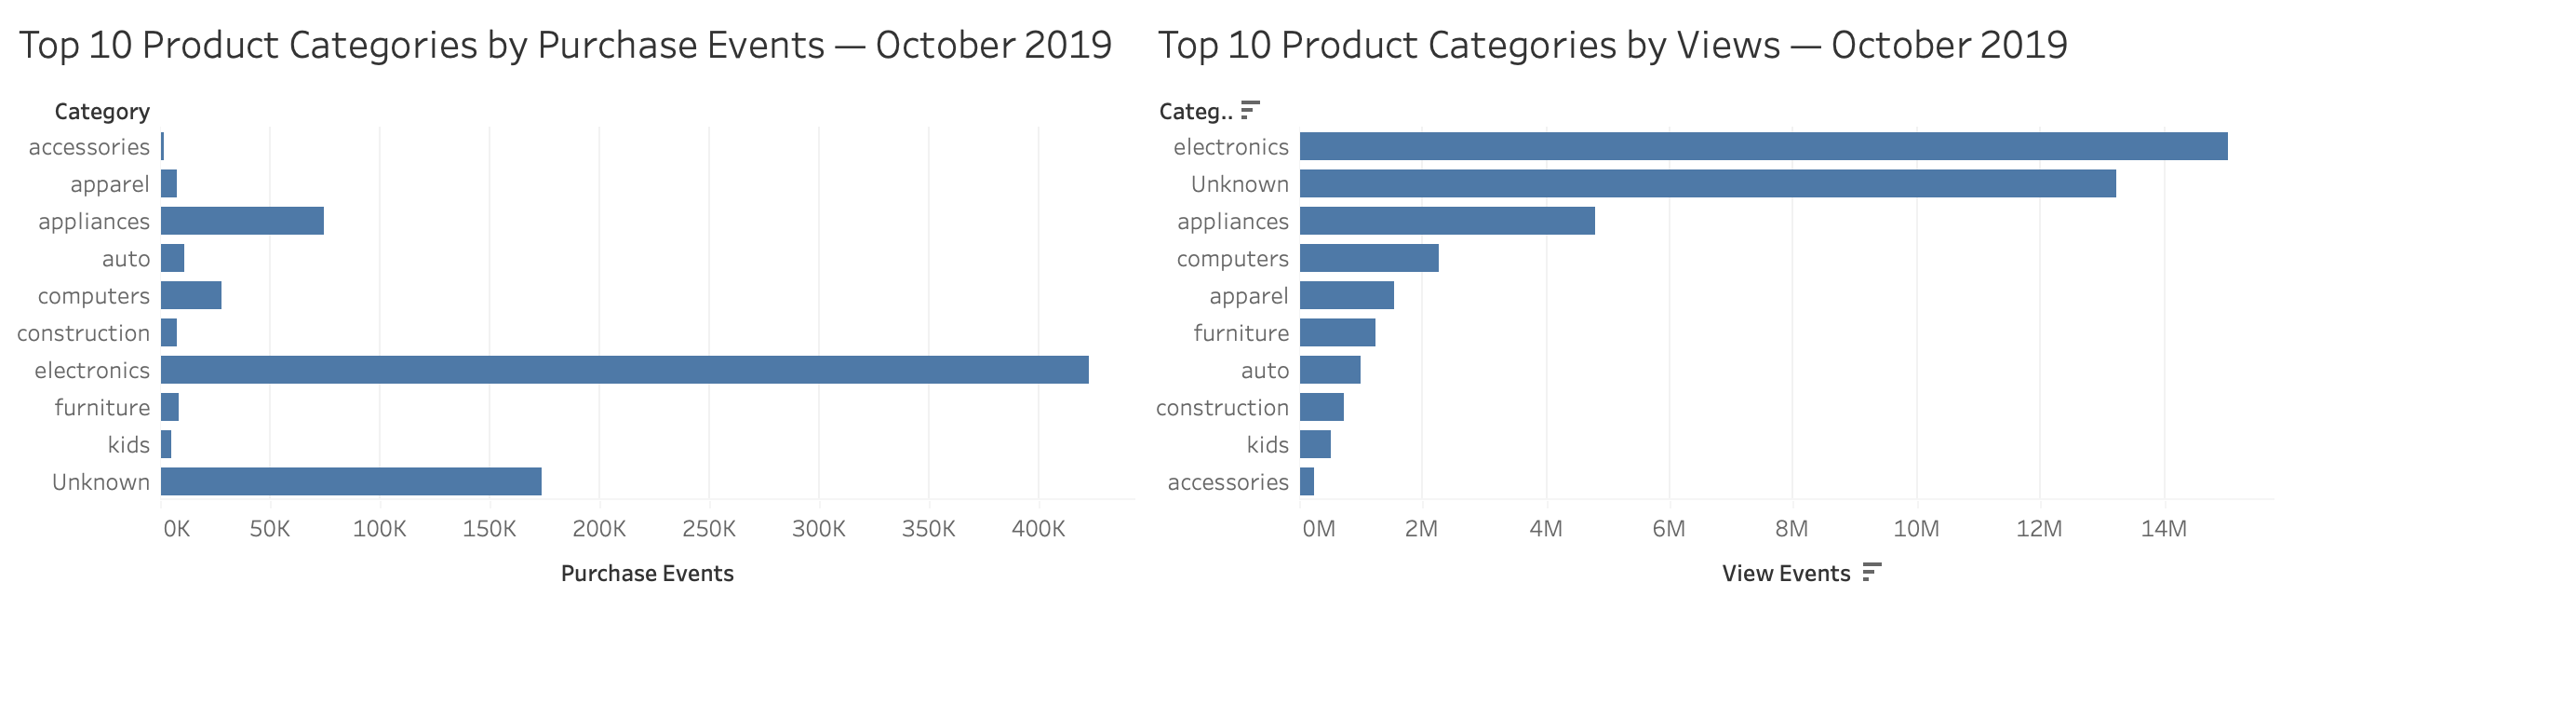

**Figure 3. Tableau Dashboard — Daily Activity and Trends**

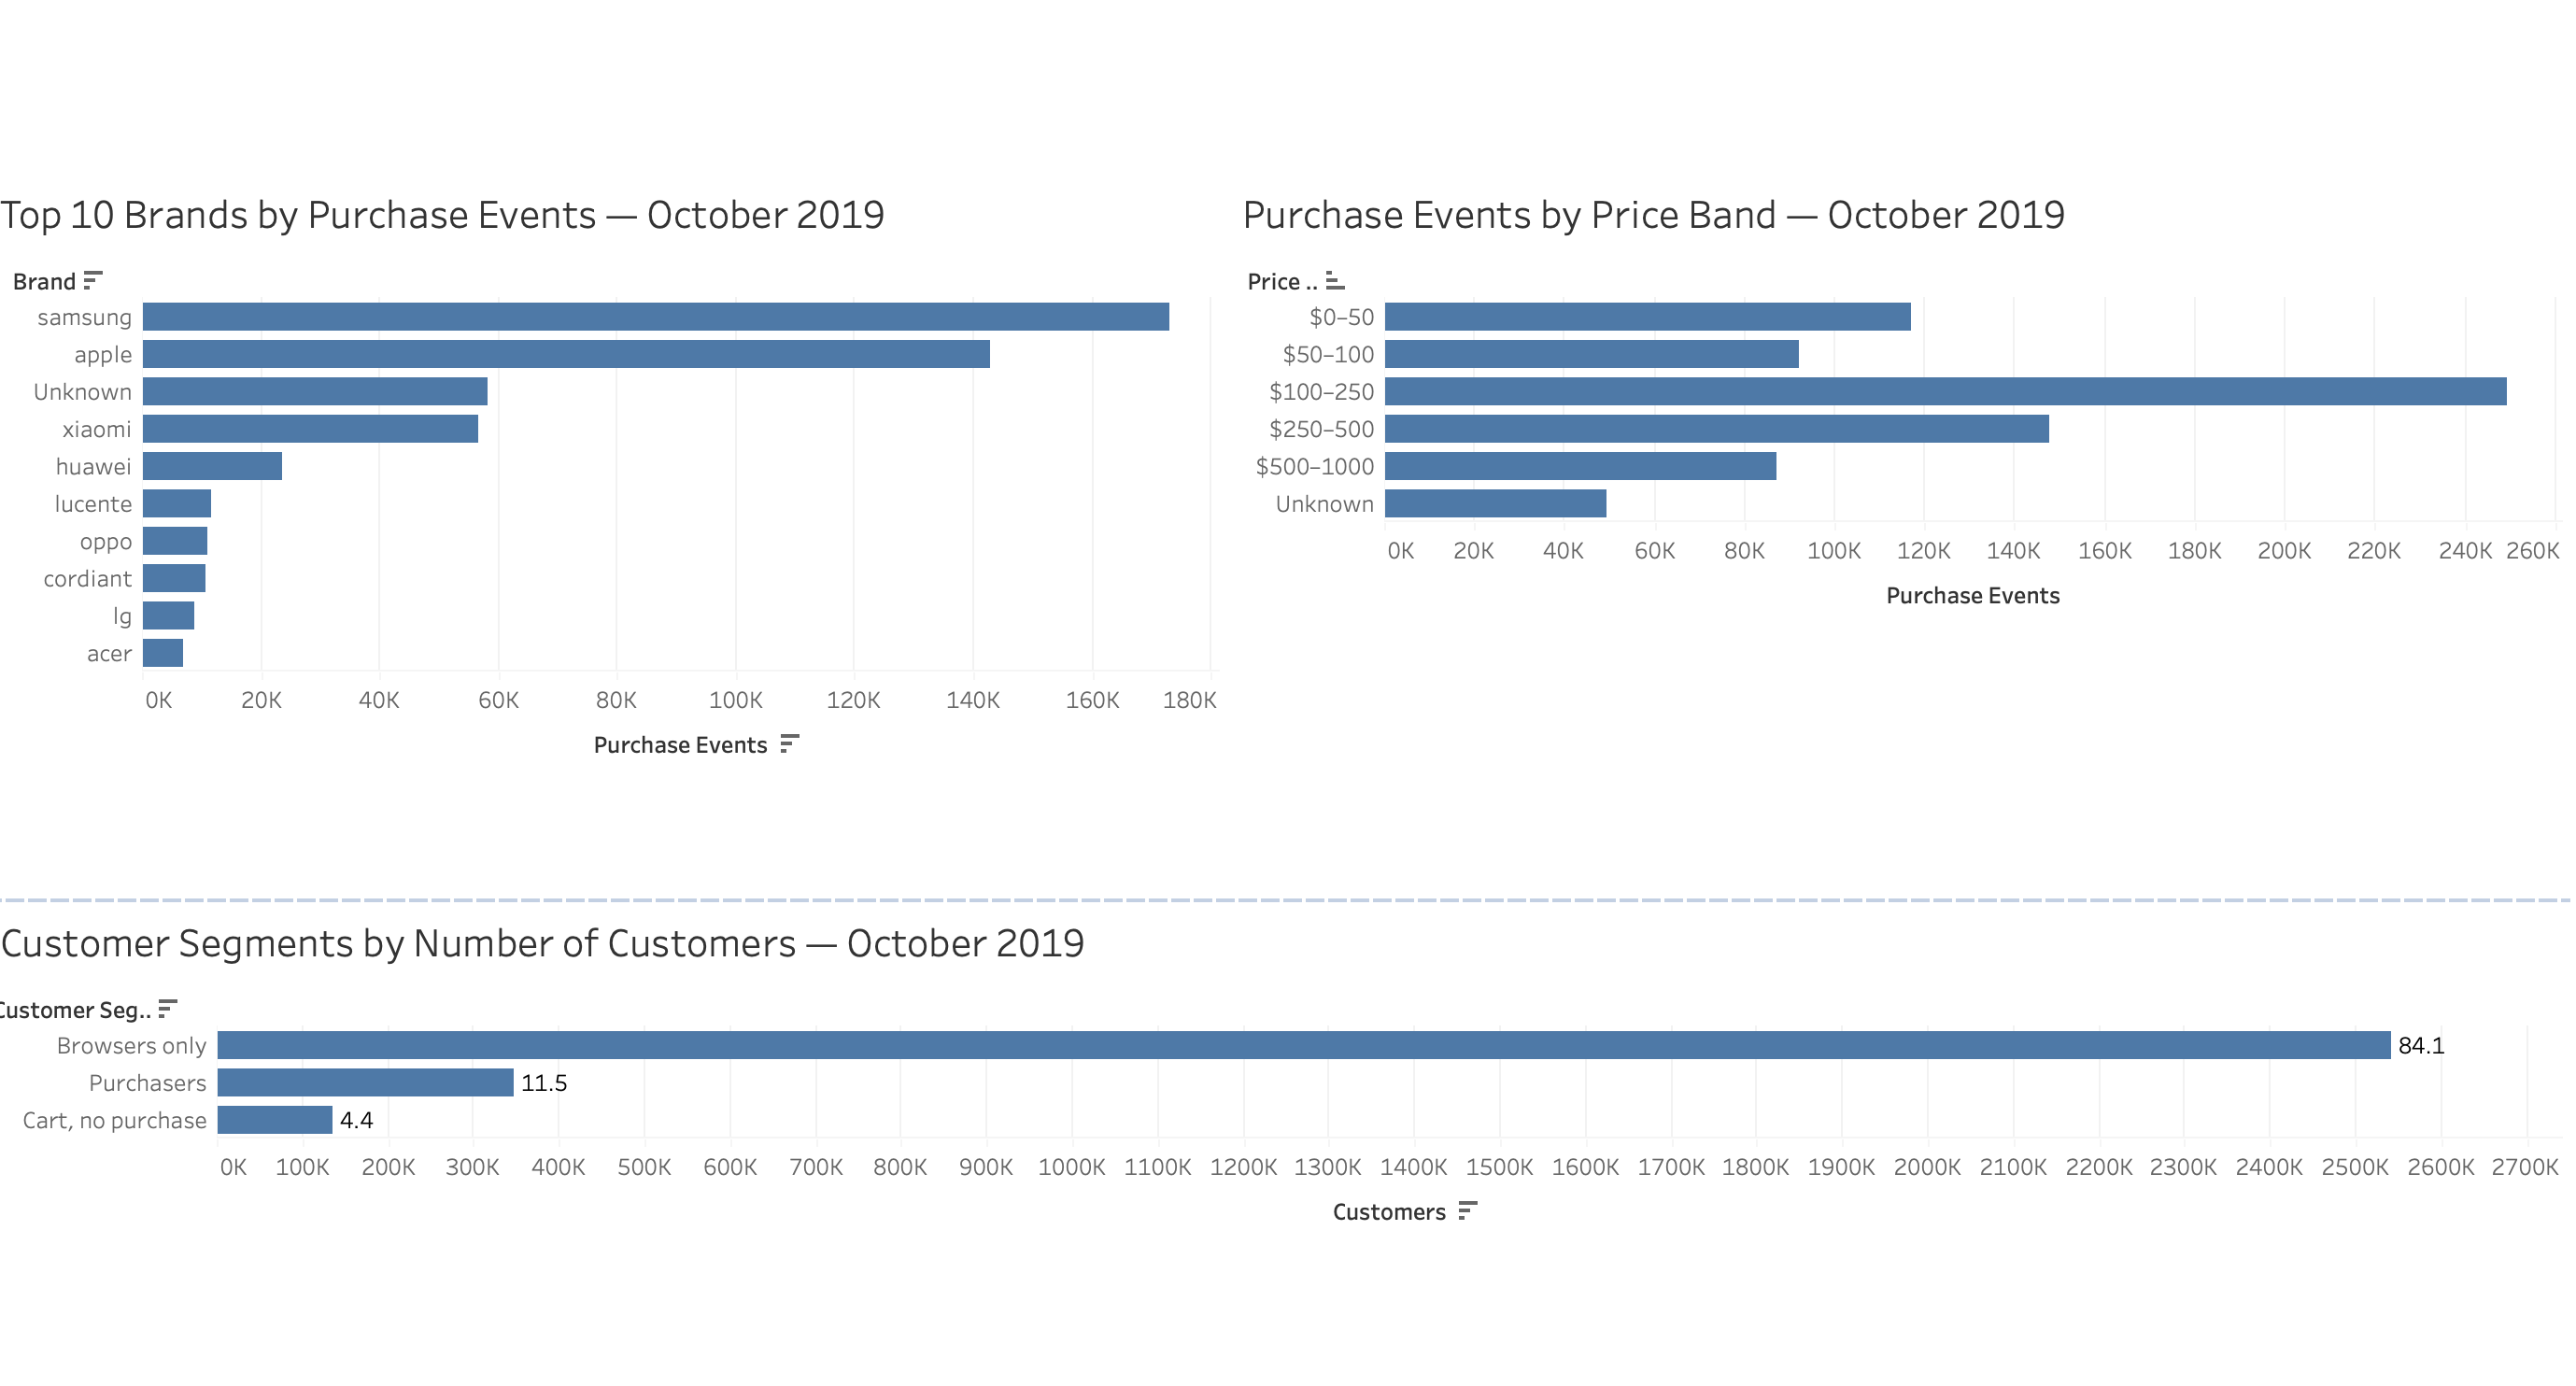

In [11]:
from IPython.display import Image, display, Markdown

# Screenshot 1
display(Markdown("**Figure 1. Tableau Dashboard — Product Performance**"))
display(Image(
    filename="Screenshot 2026-10-11 at 7.23.20\u202fPM.png",
    width=700
))

# Screenshot 2
display(Markdown("**Figure 2. Tableau Dashboard — Price Bands and Customer Segments**"))
display(Image(
    filename="Screenshot 2026-10-11 at 7.23.36\u202fPM.png",
    width=700
))

# Screenshot 3
display(Markdown("**Figure 3. Tableau Dashboard — Daily Activity and Trends**"))
display(Image(
    filename="Screenshot 2026-10-11 at 7.22.33\u202fPM.png",
    width=700
))


## Tableau Dashboard and Visualisation


Tableau Public was used to create an interactive dashboard to present the findings from the e-commerce event dataset for October 2019. The dashboard complements the Python exploratory data analysis and SQL queries by providing a visual overview of customer activity and product performance.

The dashboard contains visualisations of daily views, cart events and purchase events, the top 10 product categories by views and purchases, the top 10 brands by purchase events, and purchase events across different price bands. A customer segment chart was also included to compare the numbers and proportions of customers classified as browsers only, customers who added items to their carts without purchasing, and purchasers.

These visualisations help identify patterns in customer activity and differences in product engagement and purchase activity across categories, brands and price bands. The customer segment chart provides an additional perspective on customer behaviour during the observation period.

The dashboard should be interpreted alongside the limitations of the dataset. Event counts do not directly represent unique customers or conversion rates, and the customer segments describe activity observed during October rather than confirmed sequential customer journeys.


# 10 Overall Business Insights, Recommendations and Conclusion

## 10.1 Key Business Insights

The analysis of e-commerce behaviour during October 2019 revealed several patterns relevant to understanding customer engagement and purchase activity.

First, browsing activity accounted for the majority of recorded events, while a large proportion of customers were classified as browsers who did not record cart additions or purchases during the observation period. This suggests an opportunity to investigate how product discovery, product information, pricing, and the shopping experience could encourage further engagement. However, these customers should not automatically be considered lost sales, as their reasons for browsing without purchasing are unknown.

Second, product performance varied across categories, brands, and price bands. Electronics recorded the highest purchase volume among the main product categories, while products priced between $100 and $250 accounted for a substantial share of purchase events. These patterns can help businesses identify areas for further investigation when planning product promotions and merchandising strategies.

Third, customer activity varied across different times of the day and days of the week. Browsing activity peaked in the afternoon, whereas cart and purchase activity peaked in the morning. Average daily activity was also higher on weekends than on weekdays. These differences suggest that businesses could investigate whether promotional campaigns and marketing activities perform differently across time periods.

Finally, statistical analysis identified differences in product prices across event types and weak positive associations between average product prices and product activity counts. These findings provide additional context for understanding product behaviour, but they do not establish that price causes higher engagement or purchasing activity. The SQL analysis and Tableau dashboard further supported the investigation of product performance and the communication of key trends.

## 10.2 Business Recommendations

Based on the findings, the following recommendations could be considered:

1. Improve product discovery and engagement. Review product-page information, images, descriptions, and navigation to identify potential improvements that encourage customers to explore products further.

2. Investigate potential checkout barriers. Examine the customer journey from product views to cart additions and purchases to identify where engagement decreases. More detailed sequential session analysis would help distinguish genuine conversion drop-offs from simple event overlap.

3. Review category and price-band performance. Investigate the products and categories generating the most purchase activity, including the $100–250 price band, to inform merchandising and promotional decisions. Purchase counts should be considered alongside product availability, traffic, and revenue where those data are available.

4. Optimise campaign timing. Test whether promotions and customer communications perform better at different times of the day or on weekends. Campaign effectiveness should be measured using appropriate engagement and conversion metrics rather than activity volume alone.

5. Use customer segmentation to guide further investigation. Examine browsing only customers and customers who recorded cart activity without a purchase to understand their behaviour. Any re-engagement campaigns should be tested to determine whether they improve subsequent purchases.

## 10.3 Project Limitations

Several limitations should be considered when interpreting the results:

* Limited observation period: The dataset covers October 2019 only, so the findings may not reflect longer-term trends, seasonality, or current customer behaviour.
* Missing information: Some product category and brand fields were missing, limiting the completeness of product-level comparisons.
* Event data rather than complete transactions: Views, cart additions, and purchase events describe recorded interactions but do not provide a complete explanation of customer intentions, checkout barriers, or purchase value.
* Customer segmentation assumptions: Segments were based on recorded activity during the observation period. They do not necessarily represent sequential customer journeys or permanent customer characteristics.
* Statistical assumptions: Repeated observations of the same products or customers may affect the independence assumptions of some statistical tests. The findings should therefore be interpreted in the context of the data and methods used.
* SQL sample size: The SQL analysis used the first one million rows rather than the full October dataset. Its findings are exploratory and may not represent the entire month.
* No causal evaluation: The analysis identifies patterns and associations but does not establish that a particular product feature, price, or marketing strategy causes customers to purchase.

## 10.4 Future Improvements

Future work could extend this project in several ways. A sequential, session-level funnel analysis could provide a clearer view of customer progression from browsing to cart additions and purchases. Additional metrics, such as revenue, average order value, and product-level conversion rates, could improve the evaluation of commercial performance if the necessary data were available.

The analysis could also be extended to multiple months to identify longer-term trends and seasonal patterns. Statistical testing could be strengthened by accounting for repeated observations and using suitable confidence intervals or other robust methods. Finally, controlled experiments, such as A/B testing changes to product pages or promotional campaigns, could help determine whether the recommended improvements produce measurable benefits.

## 10.5 Conclusion

This project demonstrated how Python-based data cleaning, exploratory data analysis, statistical analysis, SQL, customer segmentation, and Tableau visualisation can be combined to investigate e-commerce customer behaviour. The analysis identified patterns in browsing, cart additions, purchases, product performance, customer activity, and timing, providing a basis for further business investigation.

Although the findings suggest potential opportunities to improve product discovery, investigate checkout behaviour, evaluate price-band performance, and optimise marketing activities, the recommendations require further validation. The dataset's limitations mean that the results should be treated as exploratory rather than definitive evidence of customer motivations or business outcomes.

Overall, the project illustrates the value of data analytics in translating large volumes of customer event data into interpretable findings and practical recommendations. Further analysis using more complete transaction data, sequential customer journeys, longer observation periods, and controlled experiments could provide stronger evidence to support e-commerce business decisions.
